# Phân tích kinh doanh và trực quan hóa · RF-15 + FE-04

**Phương pháp.** Error = Forecast − Actual. MAE và RMSE tính ở cấp item–store–day trừ khi ghi rõ. WAPE = 100 × tổng |Error| / tổng Actual. Bias = 100 × tổng Error / tổng Actual. Tổng Actual bằng 0 trả về N/A. Tổng sai số tuyệt đối và độ lớn lệch tổng là hai đại lượng riêng.

**Nhóm biết trước.** Quy mô bán dùng tổng đơn vị d_1886–d_1913. Hai ngưỡng tercile tính theo nội suy tuyến tính trên các chuỗi có bán. Giá trị bằng ngưỡng thuộc nhóm thấp hơn, chuỗi không bán có nhóm riêng. ABC dùng tỷ trọng từ trọng số cấp 12 của evaluator, tương đương tỷ trọng doanh thu units × sell_price ở cùng cửa sổ. Xếp giảm theo trọng số, hòa theo series_id tăng dần. Chuỗi làm vượt 80% hoặc 95% vẫn ở lớp trước khi vượt. Khi đã chạm ngưỡng trong sai số số học 10⁻¹², chuỗi kế tiếp thuộc lớp sau. Doanh thu bằng 0 vào C. Evaluator gán giá 0 khi thiếu giá và lượng bán bằng 0, đồng thời dừng nếu thiếu giá tại dòng có bán.

**Các ví dụ.** Chọn theo thứ tự trình bày và loại chuỗi đã dùng. Ví dụ gián đoạn có ít nhất một ngày bán, ưu tiên số ngày 0 và sau đó là lượng bán. Ví dụ WAPE thấp chỉ xét chuỗi có Actual ít nhất bằng trung vị của nhóm có Actual dương. Các tiêu chí bằng nhau dùng series_id tăng dần. Đây là minh họa hồi cứu trên Test. RMSSE từng chuỗi và contribution lấy từ evaluator chính thức, với trọng số từ trước Test.

**Tệp phân tích.** Bảng bổ sung nằm trong reports/tables với tiền tố business_v2_. Có thể mở trực tiếp bằng Excel hoặc Power BI. Workbook chính thức và Forecast_Detail giữ dữ liệu niêm phong.

[Báo cáo và nguồn số liệu](../docs/STAGE5_BUSINESS_REPORT.md) · [Danh mục hình 300 DPI](../reports/FIGURE_CATALOG.md).

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

current = Path.cwd().resolve()
root = next(p for p in (current, *current.parents) if (p / "reports/manifest_stage5.json").is_file())
tables = root / "reports/tables"
figures = root / "reports/figures"

def show(name, columns, limit):
    frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")
    display(frame[columns].head(limit).round(4))

def figure(name):
    display(Image(filename=str(figures / name), width=1120))


## 1. Mục tiêu và phạm vi

**Câu hỏi.** Kết quả nào có thể dùng để ưu tiên theo dõi hàng bán lẻ?

- Phạm vi Test 25/04/2016–22/05/2016, 30.490 chuỗi và 853.720 dòng. Forecast có gốc d_1913.
- Đọc Actual, hai forecast và trọng số từ artifact niêm phong. Các nhóm biết trước dùng lịch sử đến forecast origin, còn xếp hạng ngoại lệ mô tả riêng cửa sổ Test.

**Ứng dụng.** Dùng bảng tổng hợp để xác định điểm cần rà soát, sau đó mở bảng chi tiết theo chuỗi.

## 2. Tổng quan

**Câu hỏi.** Mô hình mới đem lại mức cải thiện nào và còn lệch bao nhiêu?

- WRMSSE RF **0,703912** so với **0,869701** của Seasonal Naive, giảm **19,06%**.
- RF dự báo **1.178.455** trên **1.231.764** đơn vị đã bán, lệch **-53.309** đơn vị.

**Ứng dụng.** Dùng cả sai số chi tiết và độ lệch tổng lượng khi đánh giá phương án kế hoạch.

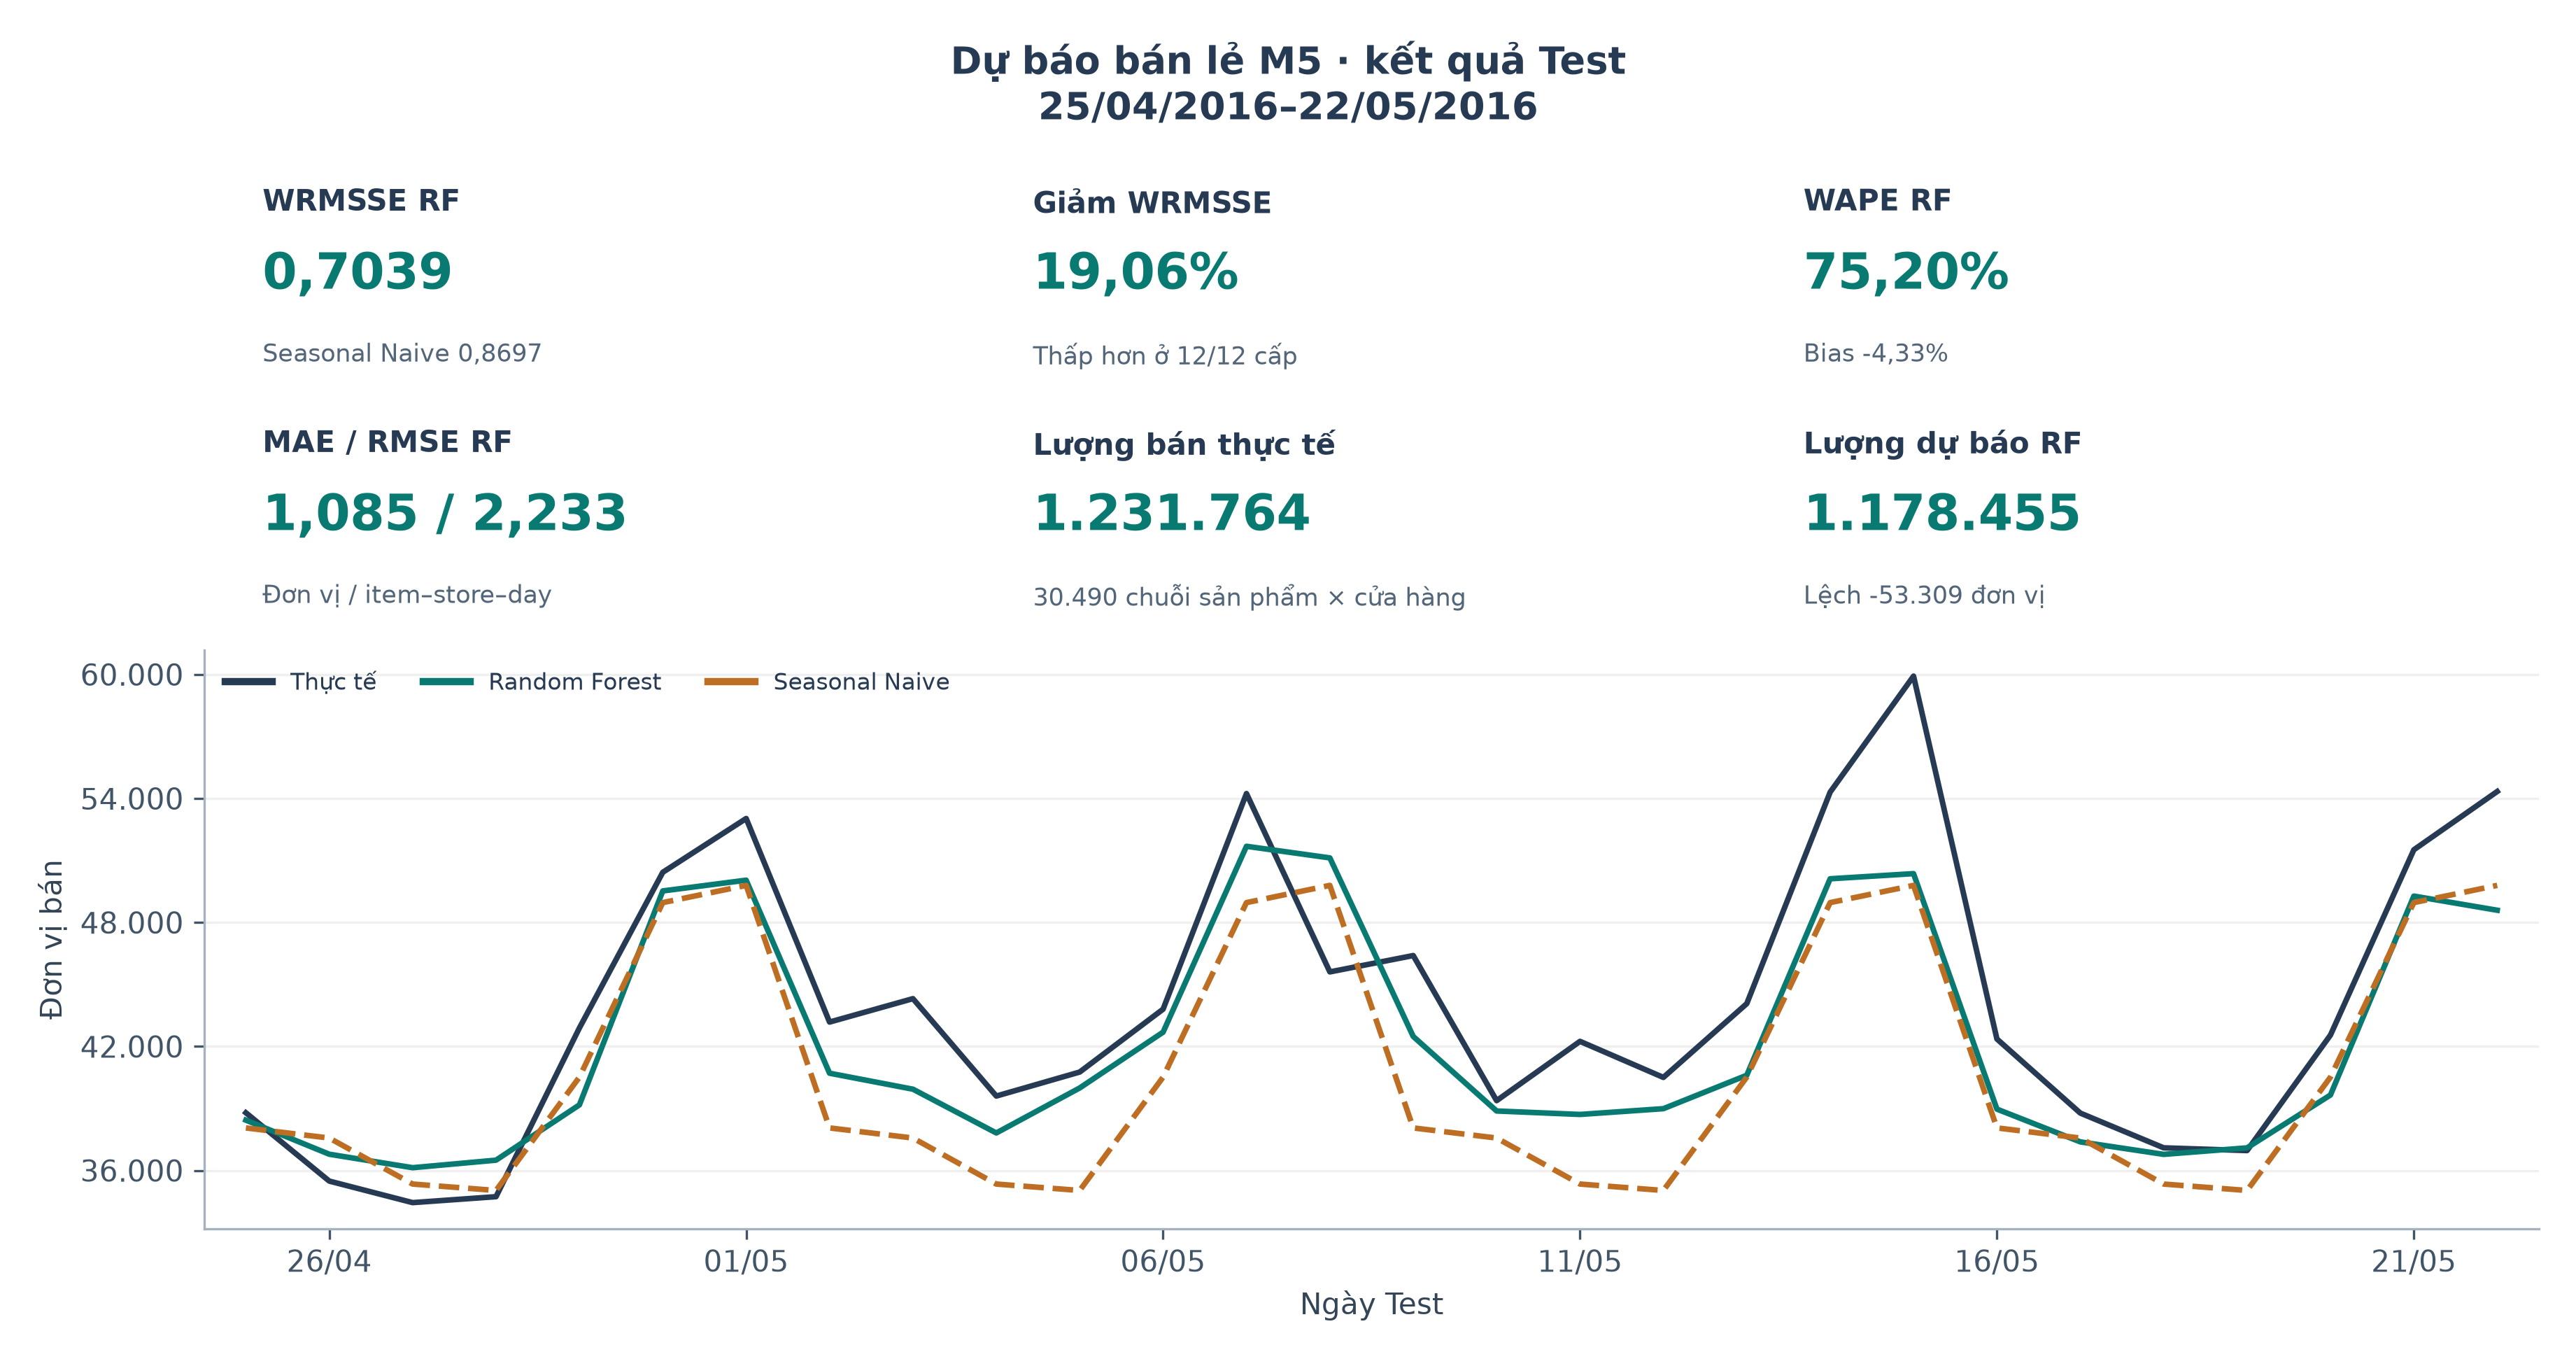

In [2]:
figure('business_v2_dashboard.png')

## 3. So sánh hiệu quả mô hình

**Câu hỏi.** Mức cải thiện có nhất quán giữa các chỉ số và cấp tổng hợp?

- WAPE giảm từ **86,22%** xuống **75,20%**, giảm **11,02 điểm %**. Bias RF là **-4,33%**.
- RF có WRMSSE thấp hơn ở **12/12 cấp**. Cấp 12 (Sản phẩm × cửa hàng) giảm tuyệt đối nhiều nhất, **0,240** điểm chuẩn hóa.
- Điểm trong cấp bằng contribution cấp nhân 12. Tổng contribution của các cấp cho WRMSSE toàn hệ thống.

**Ứng dụng.** Dùng WRMSSE M5 để đối chiếu thí nghiệm và WAPE/Bias để theo dõi sai số vận hành theo đúng độ phân giải.

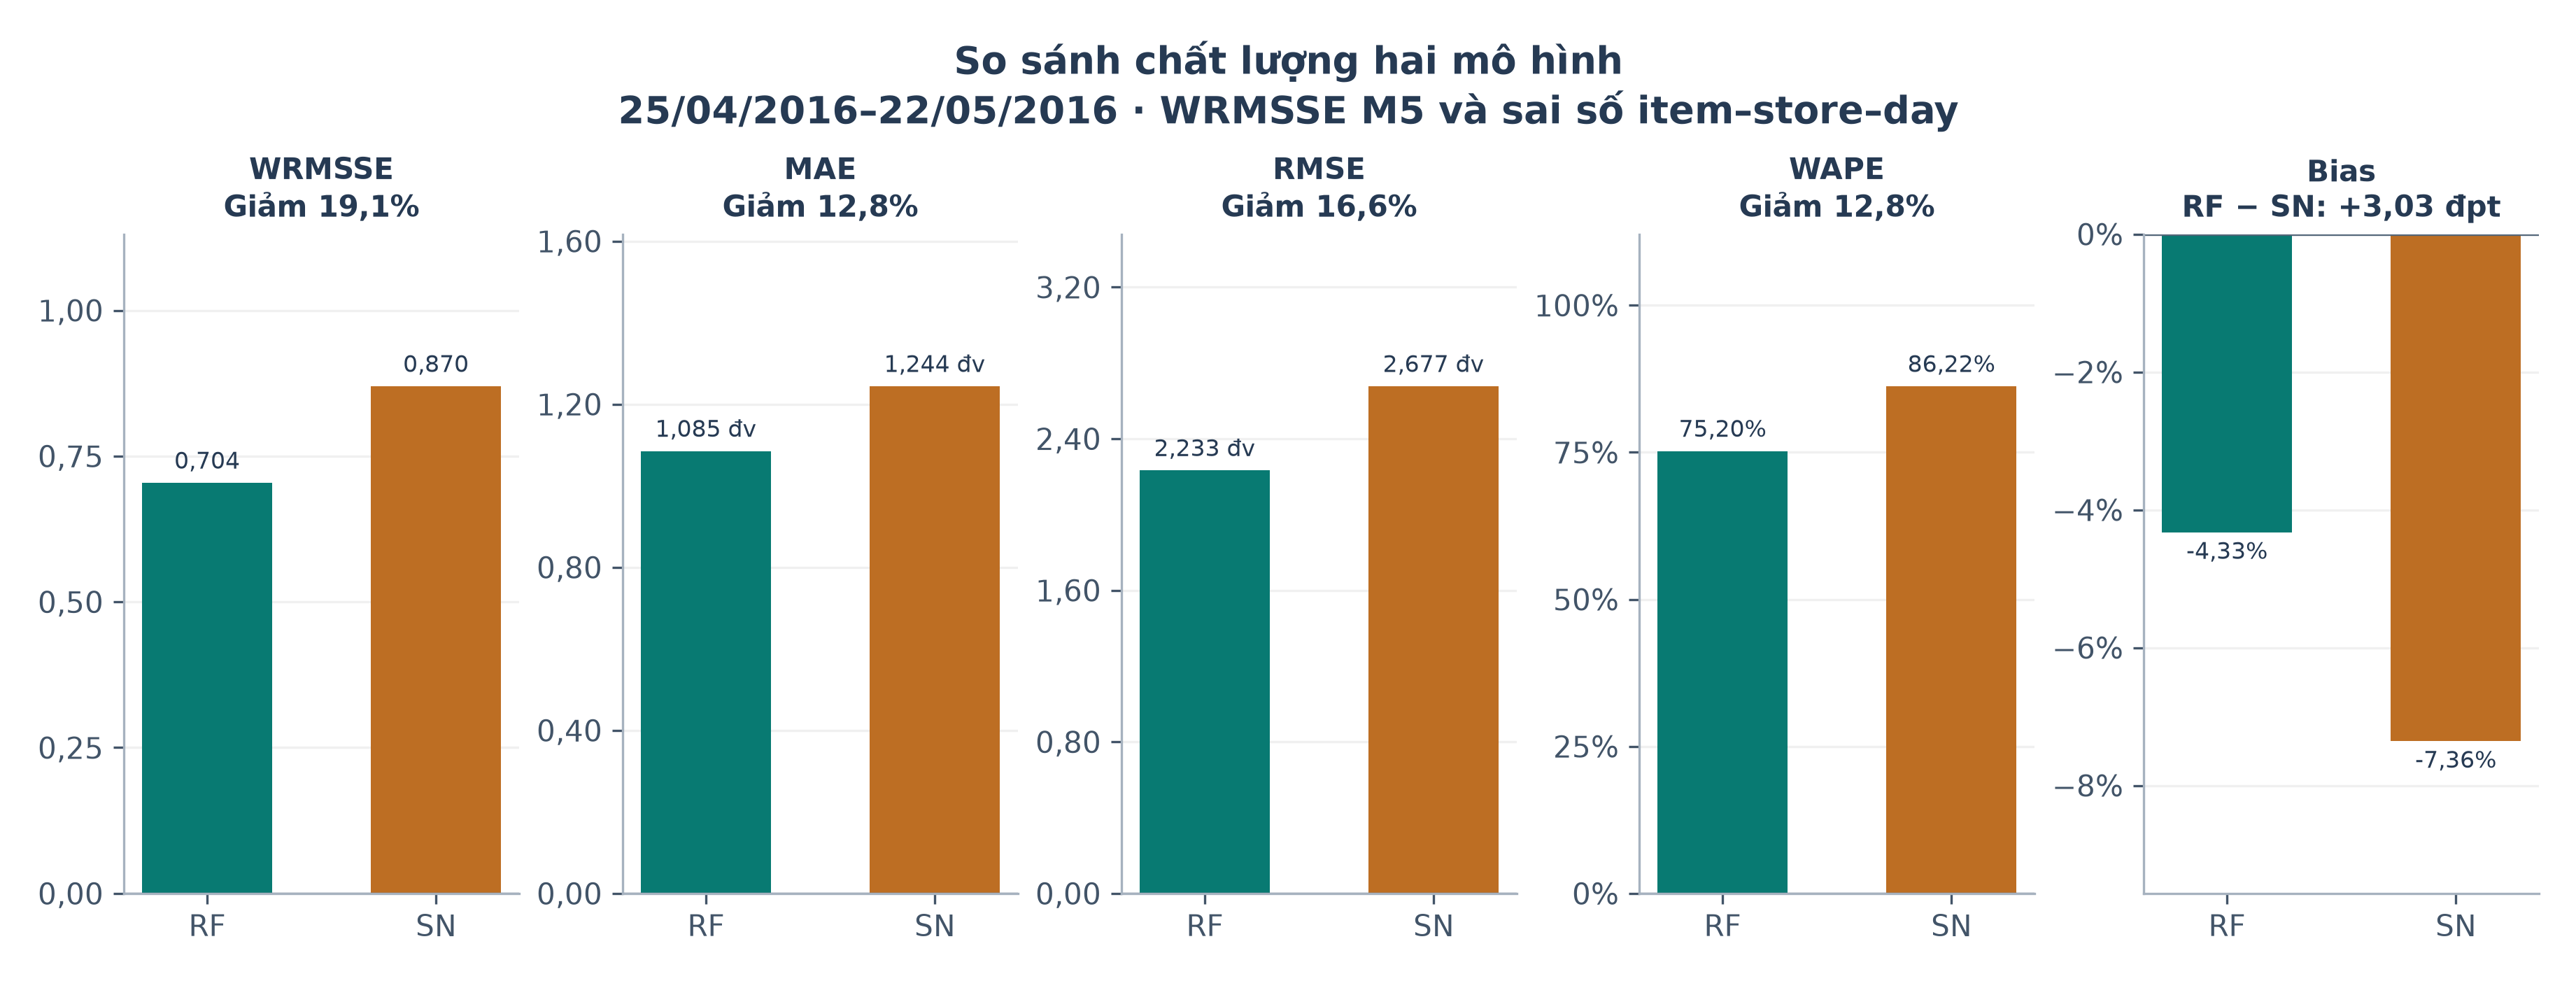

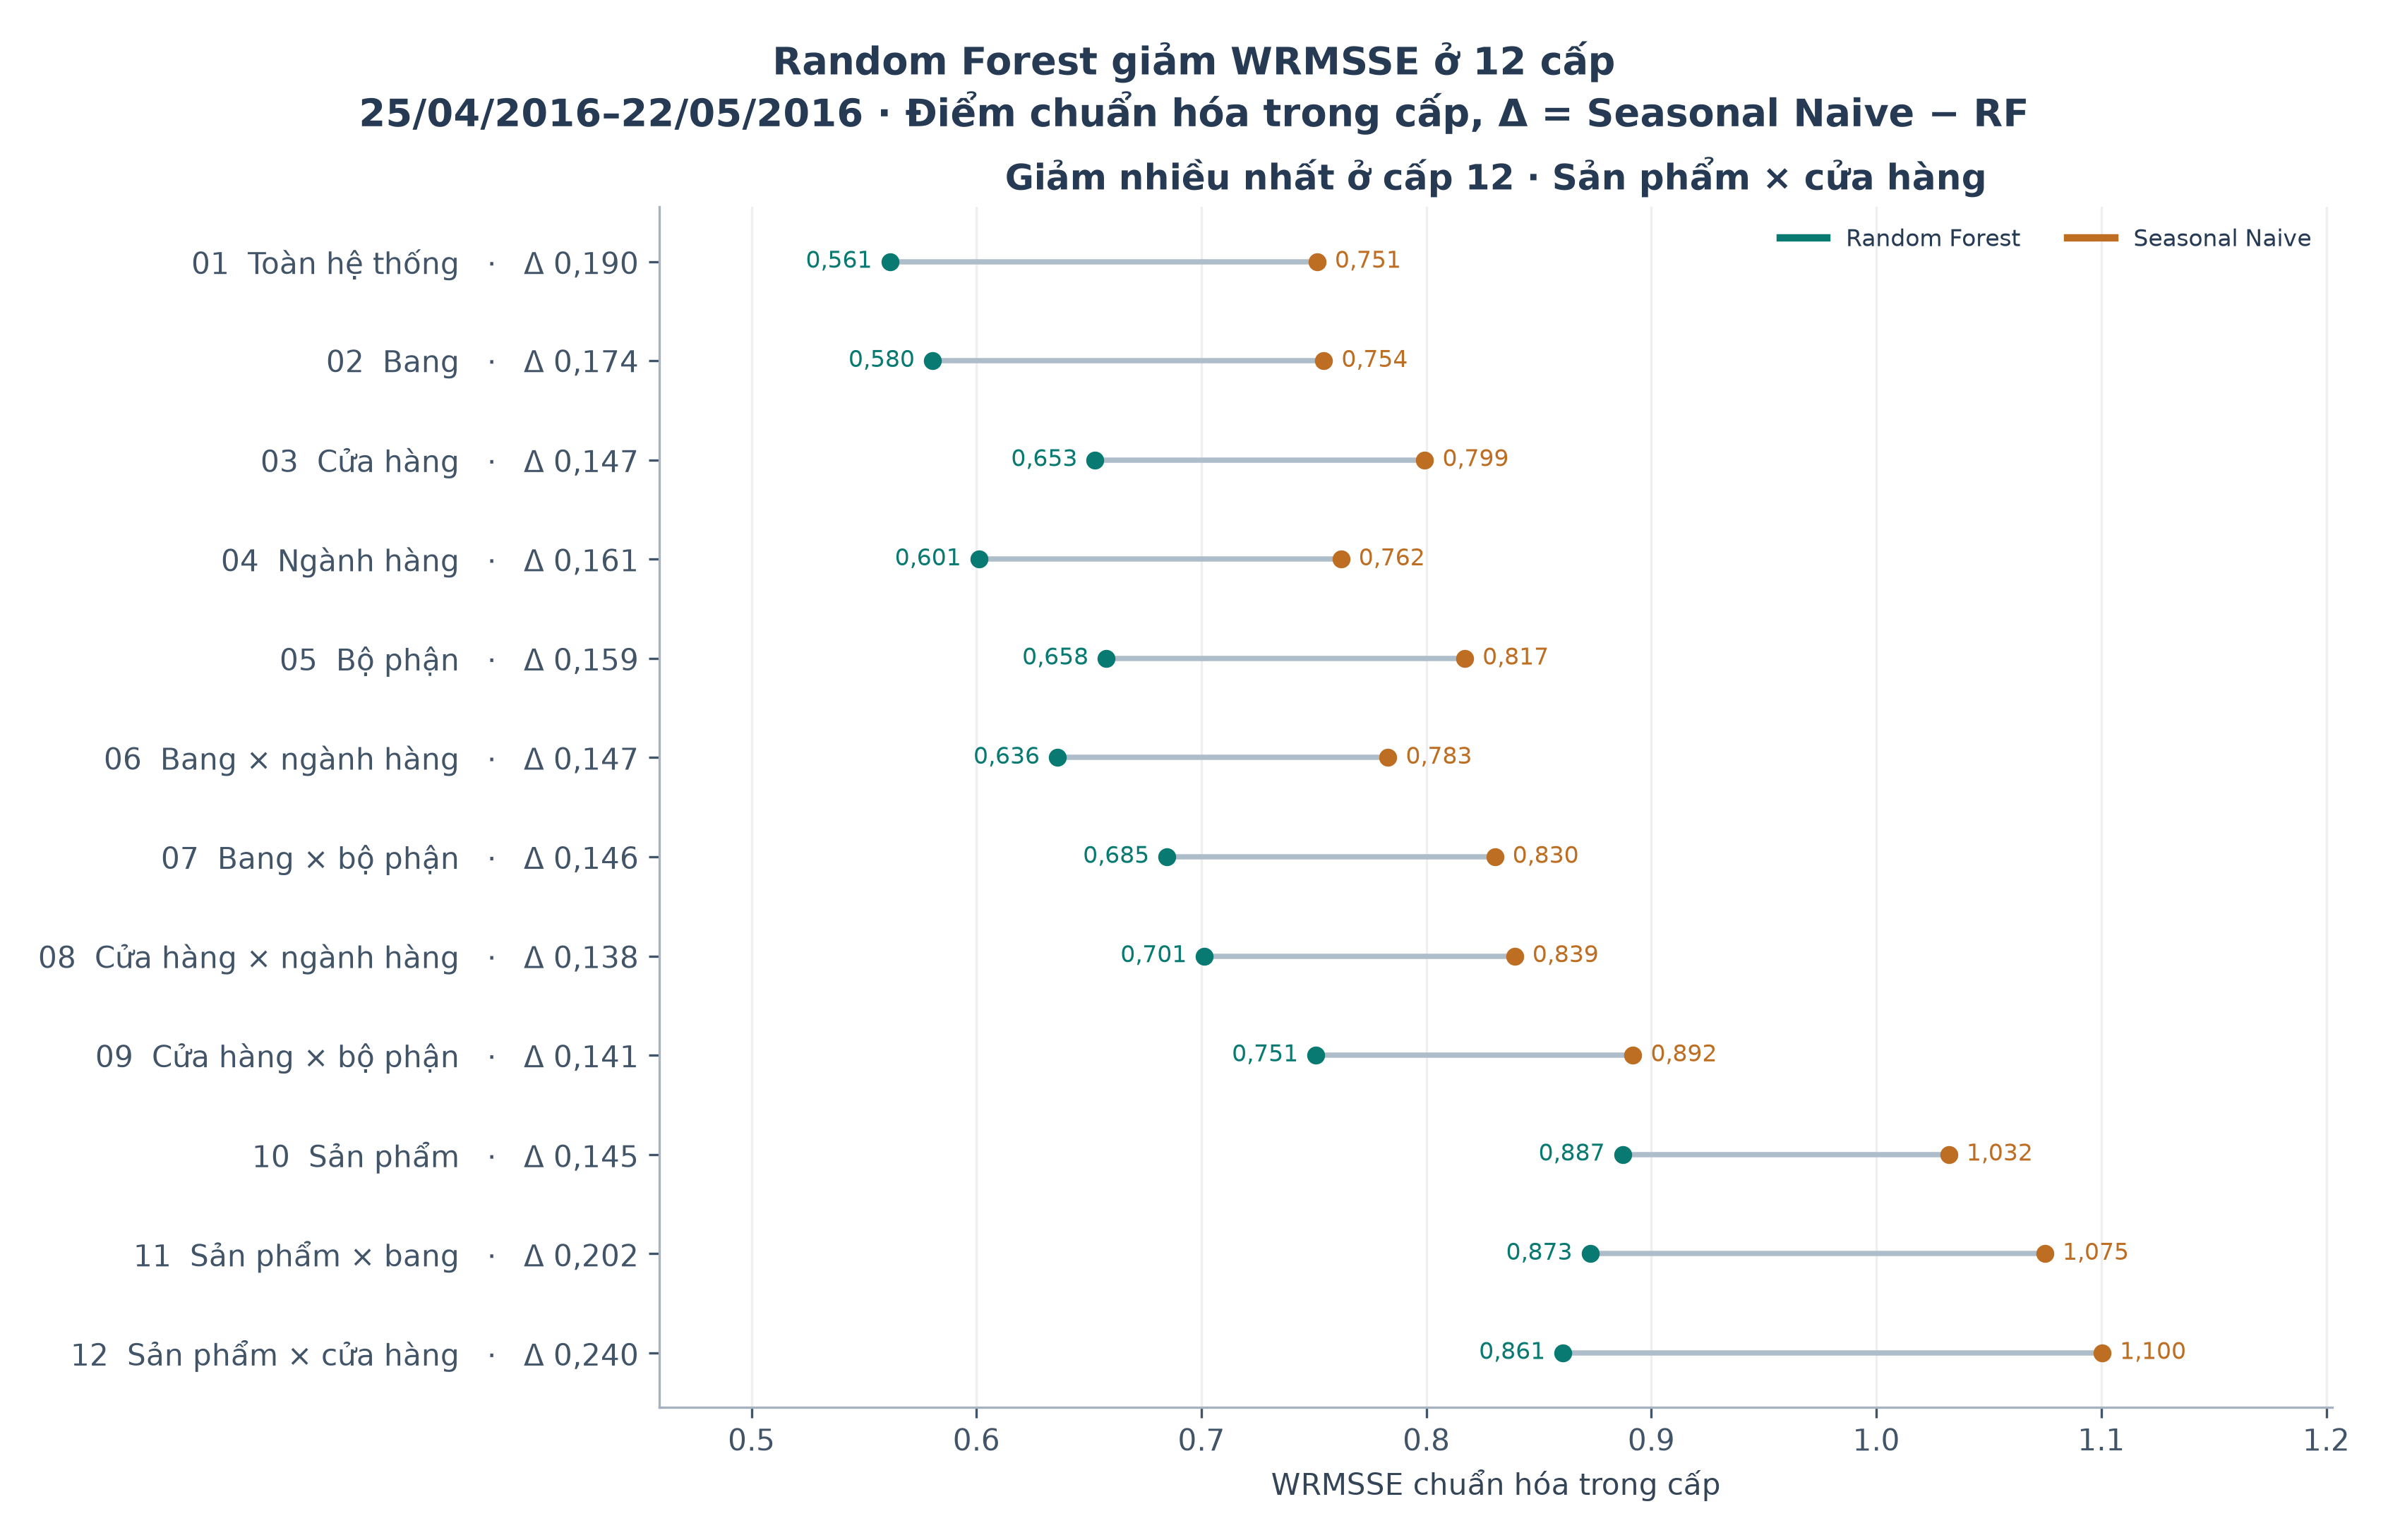

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,model,wrmsse,mae,rmse,wape_percent,forecast_bias_percent
0,random_forest,0.7039,1.085,2.2327,75.1990,-4.3279
1,seasonal_naive,0.8697,1.244,2.6769,86.2181,-7.3592


In [3]:
figure('business_v2_model_metrics.png')
figure('business_v2_hierarchy.png')
show('model_comparison', ['model', 'wrmsse', 'mae', 'rmse', 'wape_percent', 'forecast_bias_percent'], 2)

## 4. Nhu cầu theo thời gian

**Câu hỏi.** Khi nào chênh lệch tích lũy và nhịp tuần thay đổi?

- Đỉnh bán là **15/05/2016** với **59.921** đơn vị. Ngày có sai lệch RF lớn nhất là **15/05/2016**, lệch **-9.558** đơn vị.
- Đến cuối kỳ, sai lệch tích lũy của RF là **-53.309**, của SN là **-90.648** đơn vị. Sai lệch trái dấu có thể bù trừ trong tổng tích lũy.
- Tuần **3** bán nhiều nhất (**326.832**), tuần **3** có Bias RF âm nhất (**-8,16%**), tuần **1** có WAPE RF cao nhất (**76,86%**).
- **Chủ nhật** dẫn đầu bình quân với **53.225** đơn vị/ngày. Tương quan Pearson giữa tổng ngày dự báo và thực tế là **0,919** (RF) và **0,888** (SN).

**Ứng dụng.** Rà soát lịch nhập hàng theo tuần và ngày bán cao, kiểm tra lượng giao trước khi điều chỉnh kế hoạch.

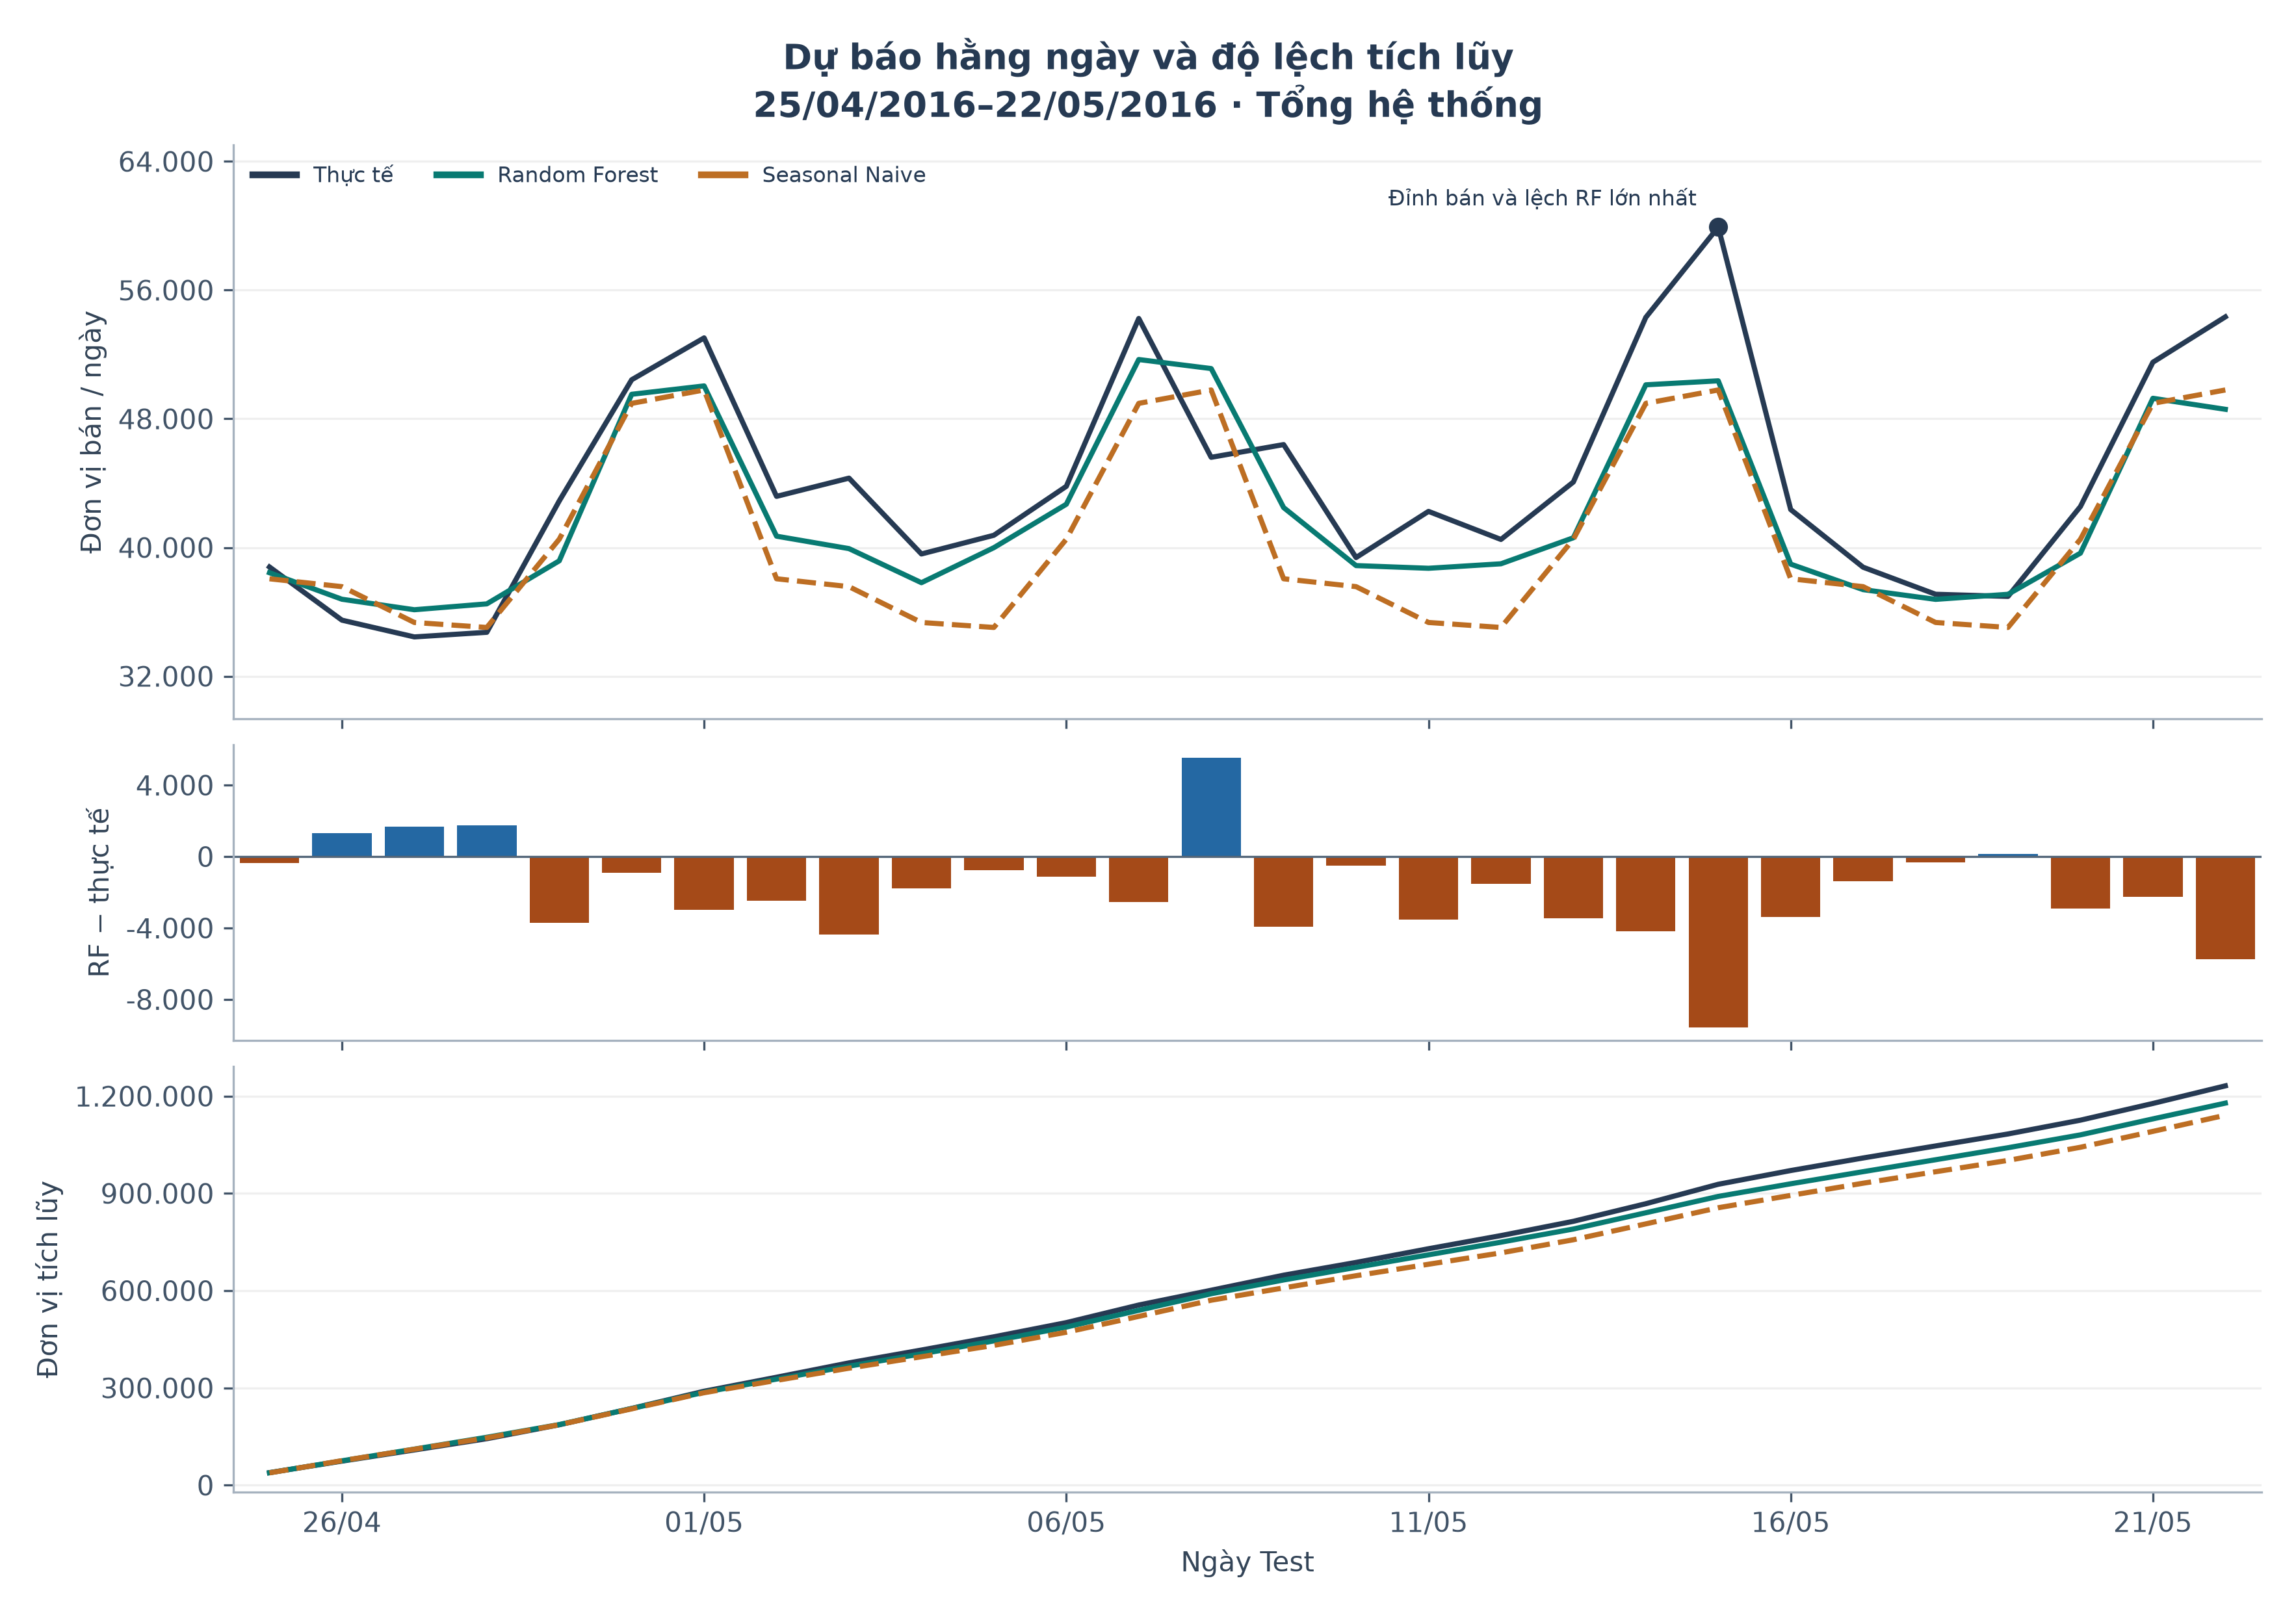

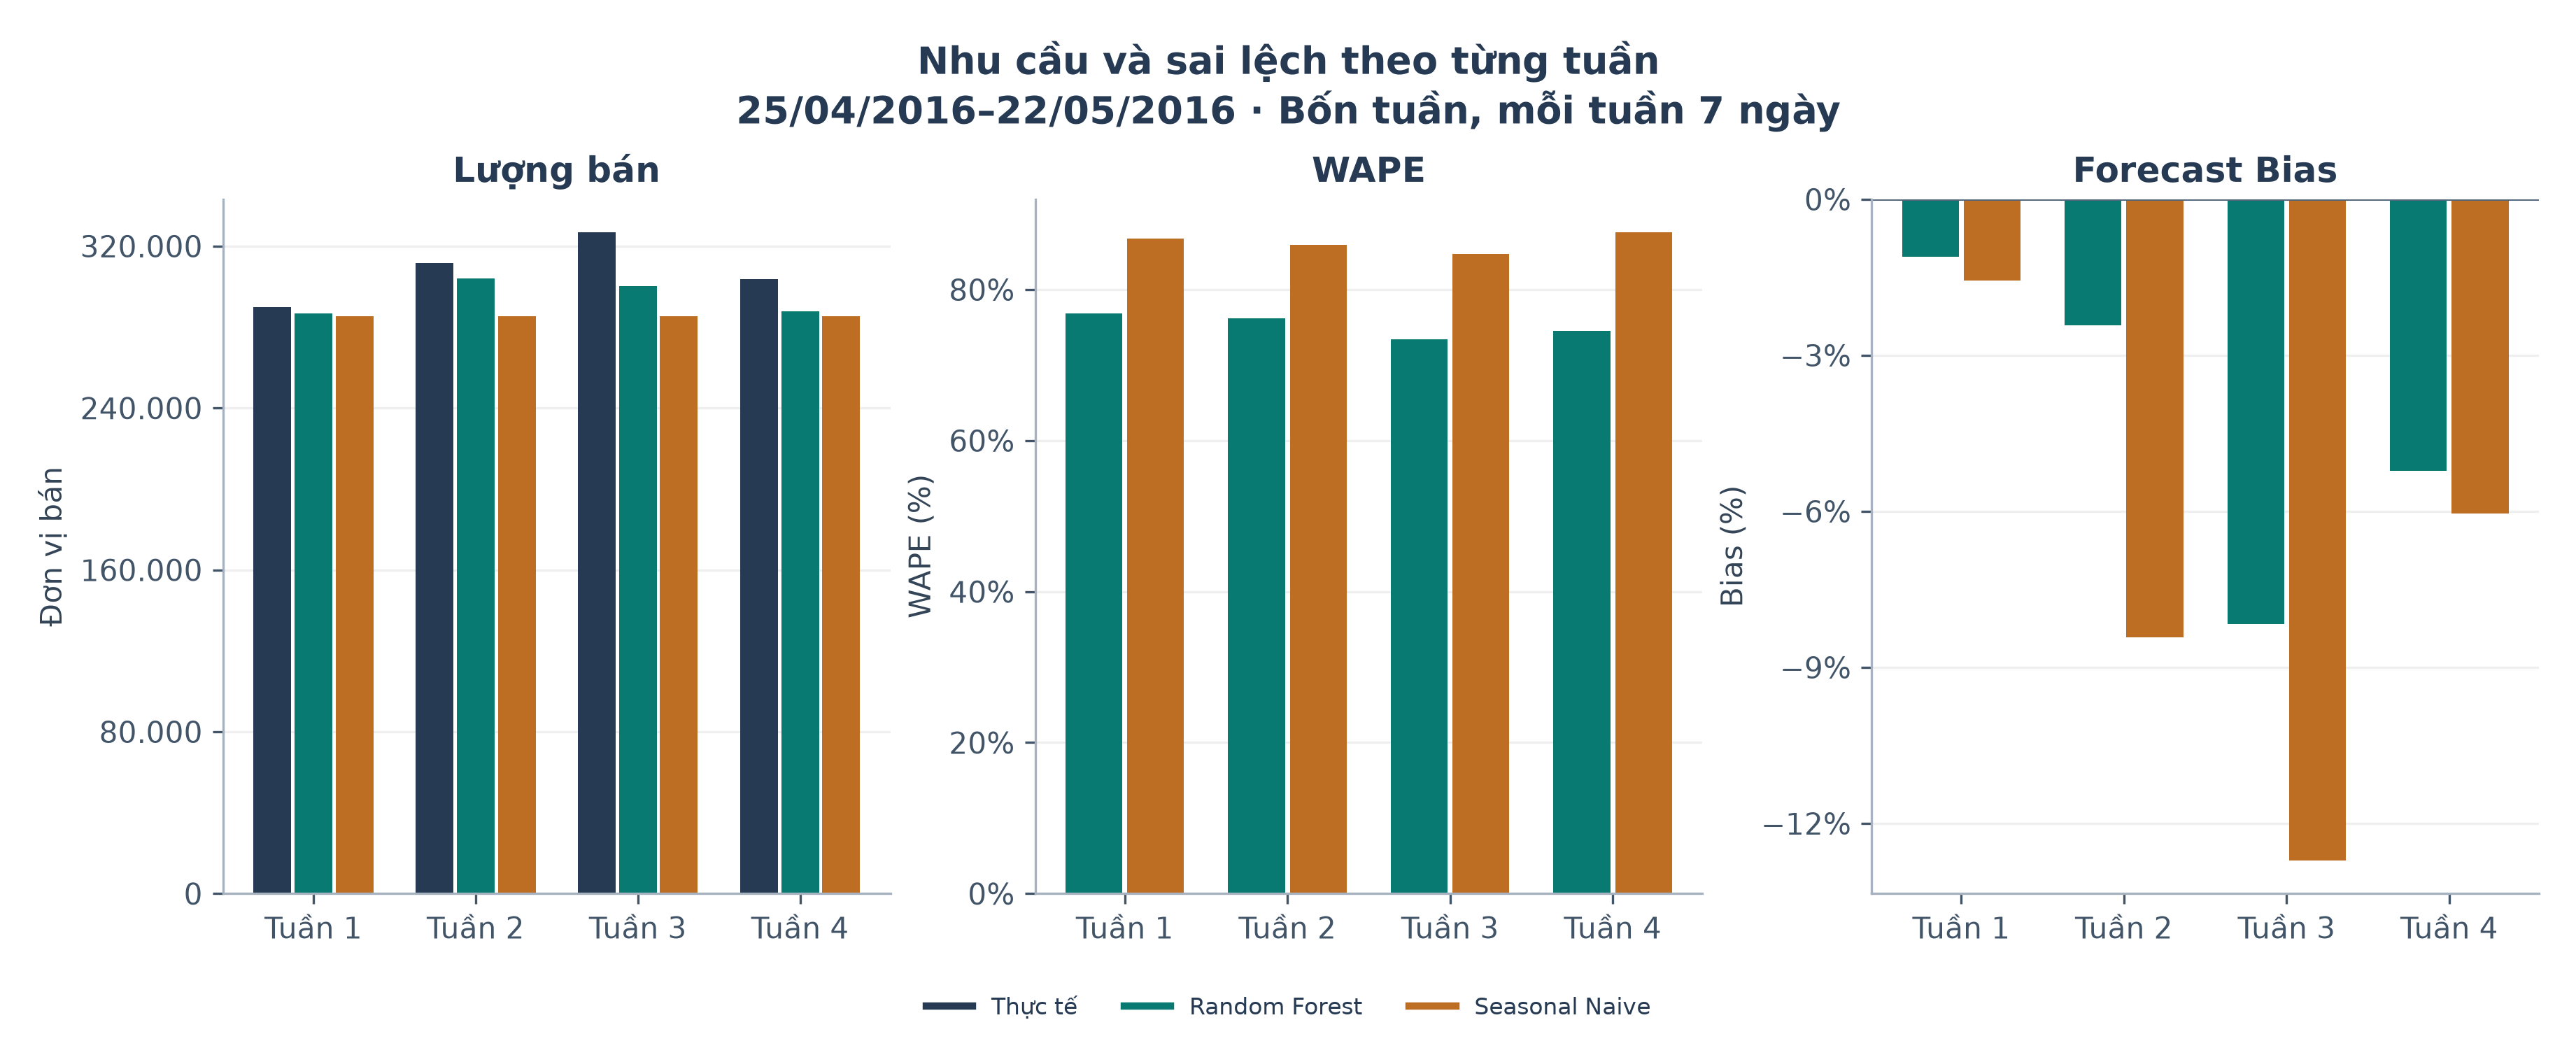

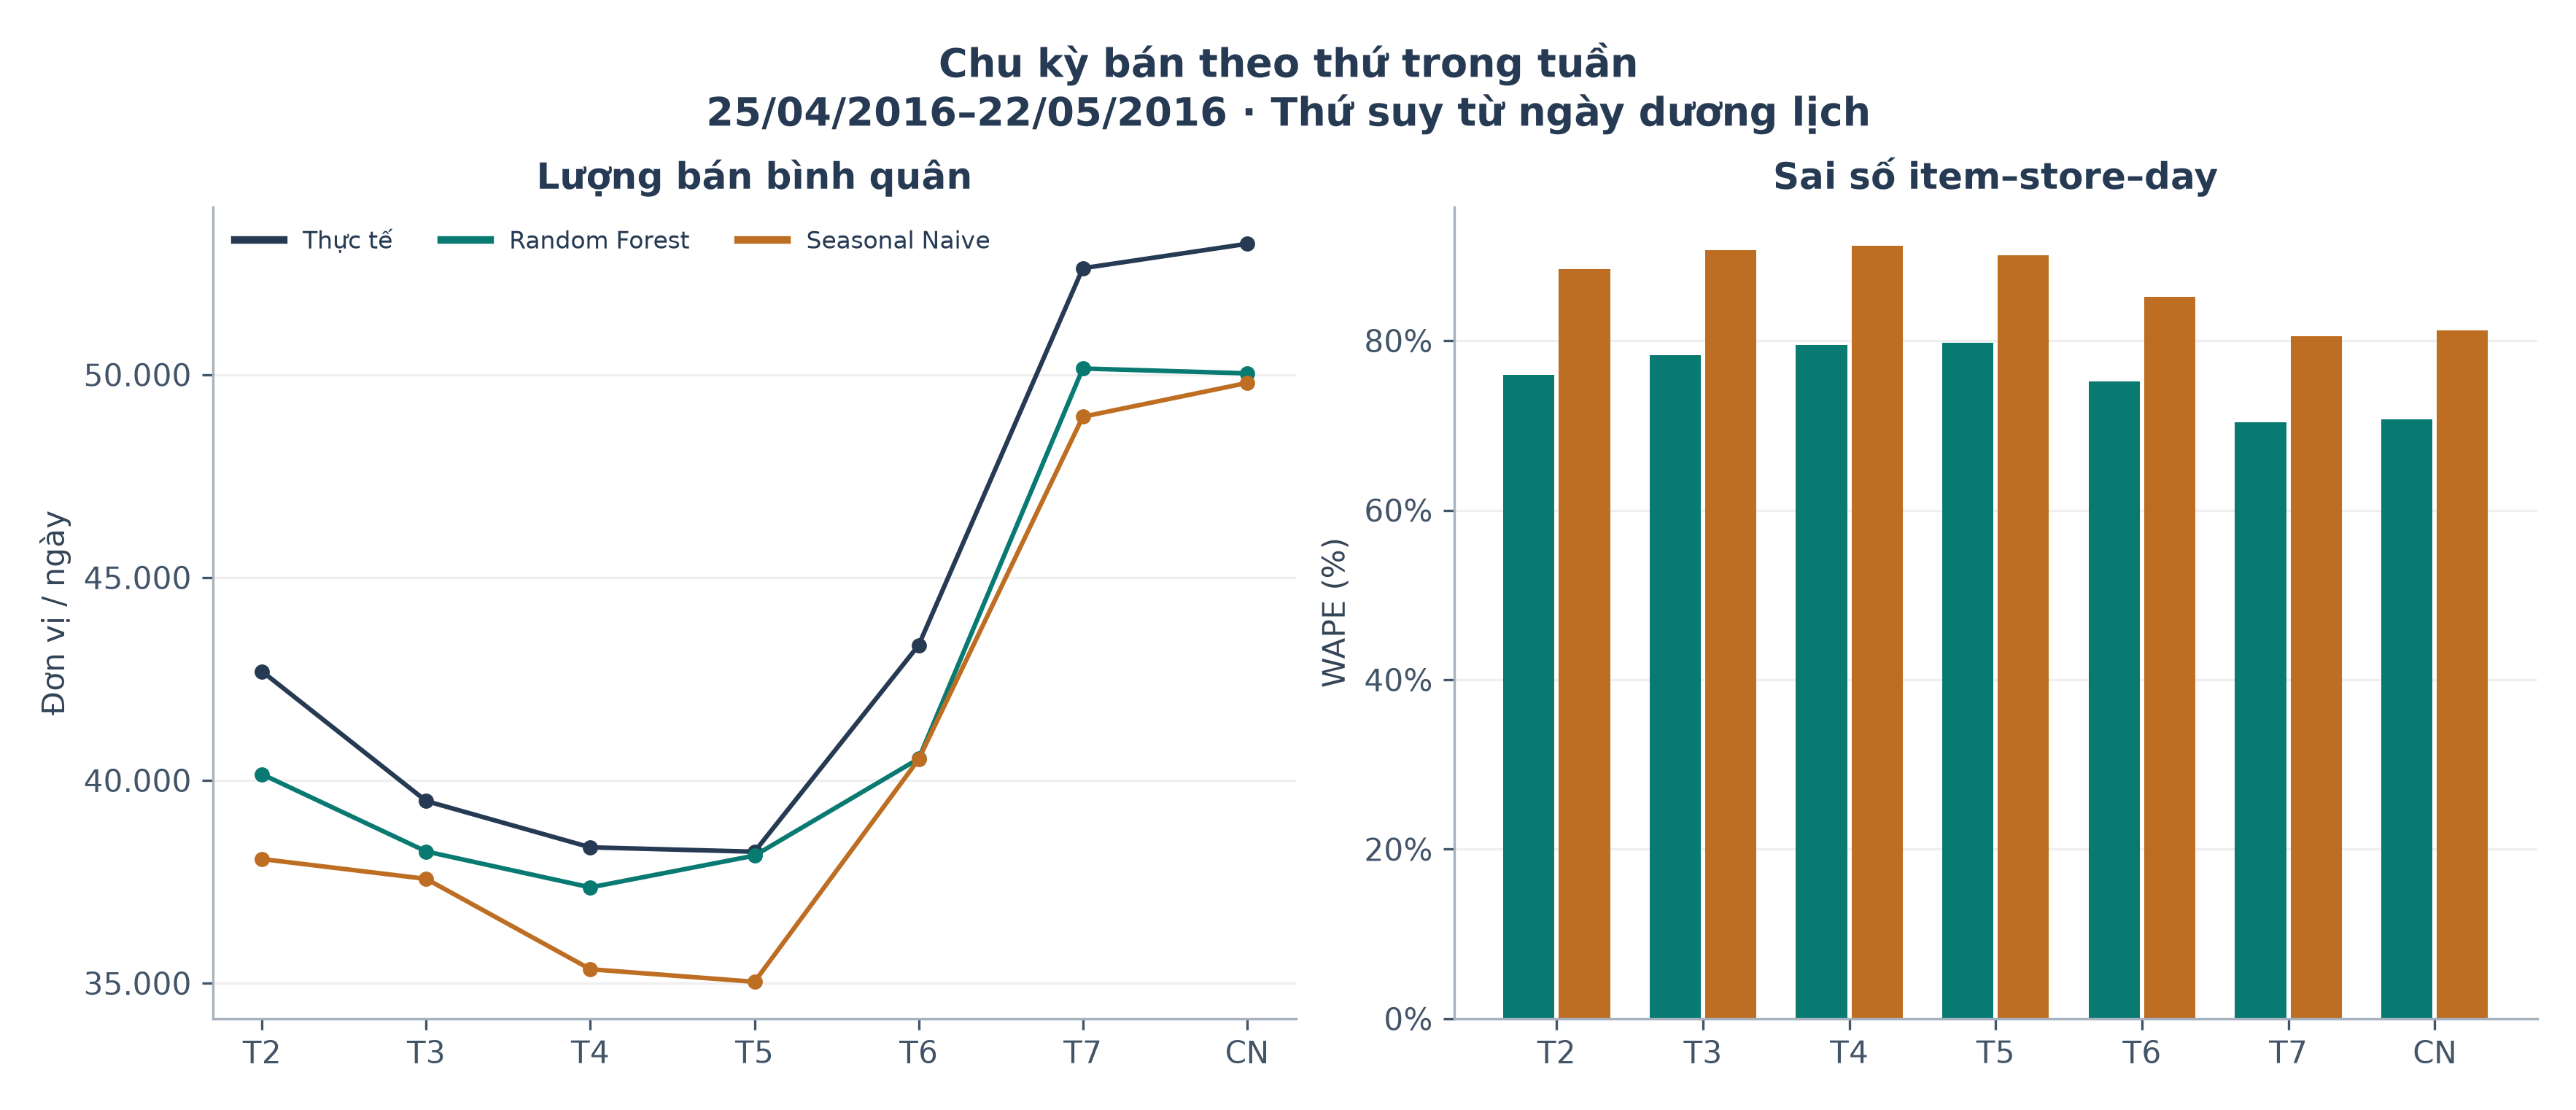

In [4]:
figure('business_v2_daily.png')
figure('business_v2_weekly.png')
figure('business_v2_weekday.png')

## 5. Bang và cửa hàng

**Câu hỏi.** Nơi nào cần ưu tiên do vừa có quy mô bán lớn vừa khó dự báo?

- **CA** chiếm **42,31%** lượng bán. RF tại bang này lệch **-22.034** đơn vị.
- **CA_4** có WAPE RF cao nhất (**90,00%**). **CA_2** có độ lệch tổng lớn nhất (**-12.418** đơn vị).
- Nhóm quy mô cao và WAPE cao gồm **CA_1, TX_3**, theo trung vị **115.934** đơn vị và **74,99%**. Giá trị bằng ngưỡng thuộc phía cao.

**Ứng dụng.** Rà soát trước nhóm cao/cao, duy trì theo dõi nhóm cao/thấp, xem nguyên nhân cục bộ ở nhóm thấp/cao và kiểm tra định kỳ nhóm thấp/thấp. Phân nhóm mô tả Test theo lượng bán và WAPE.

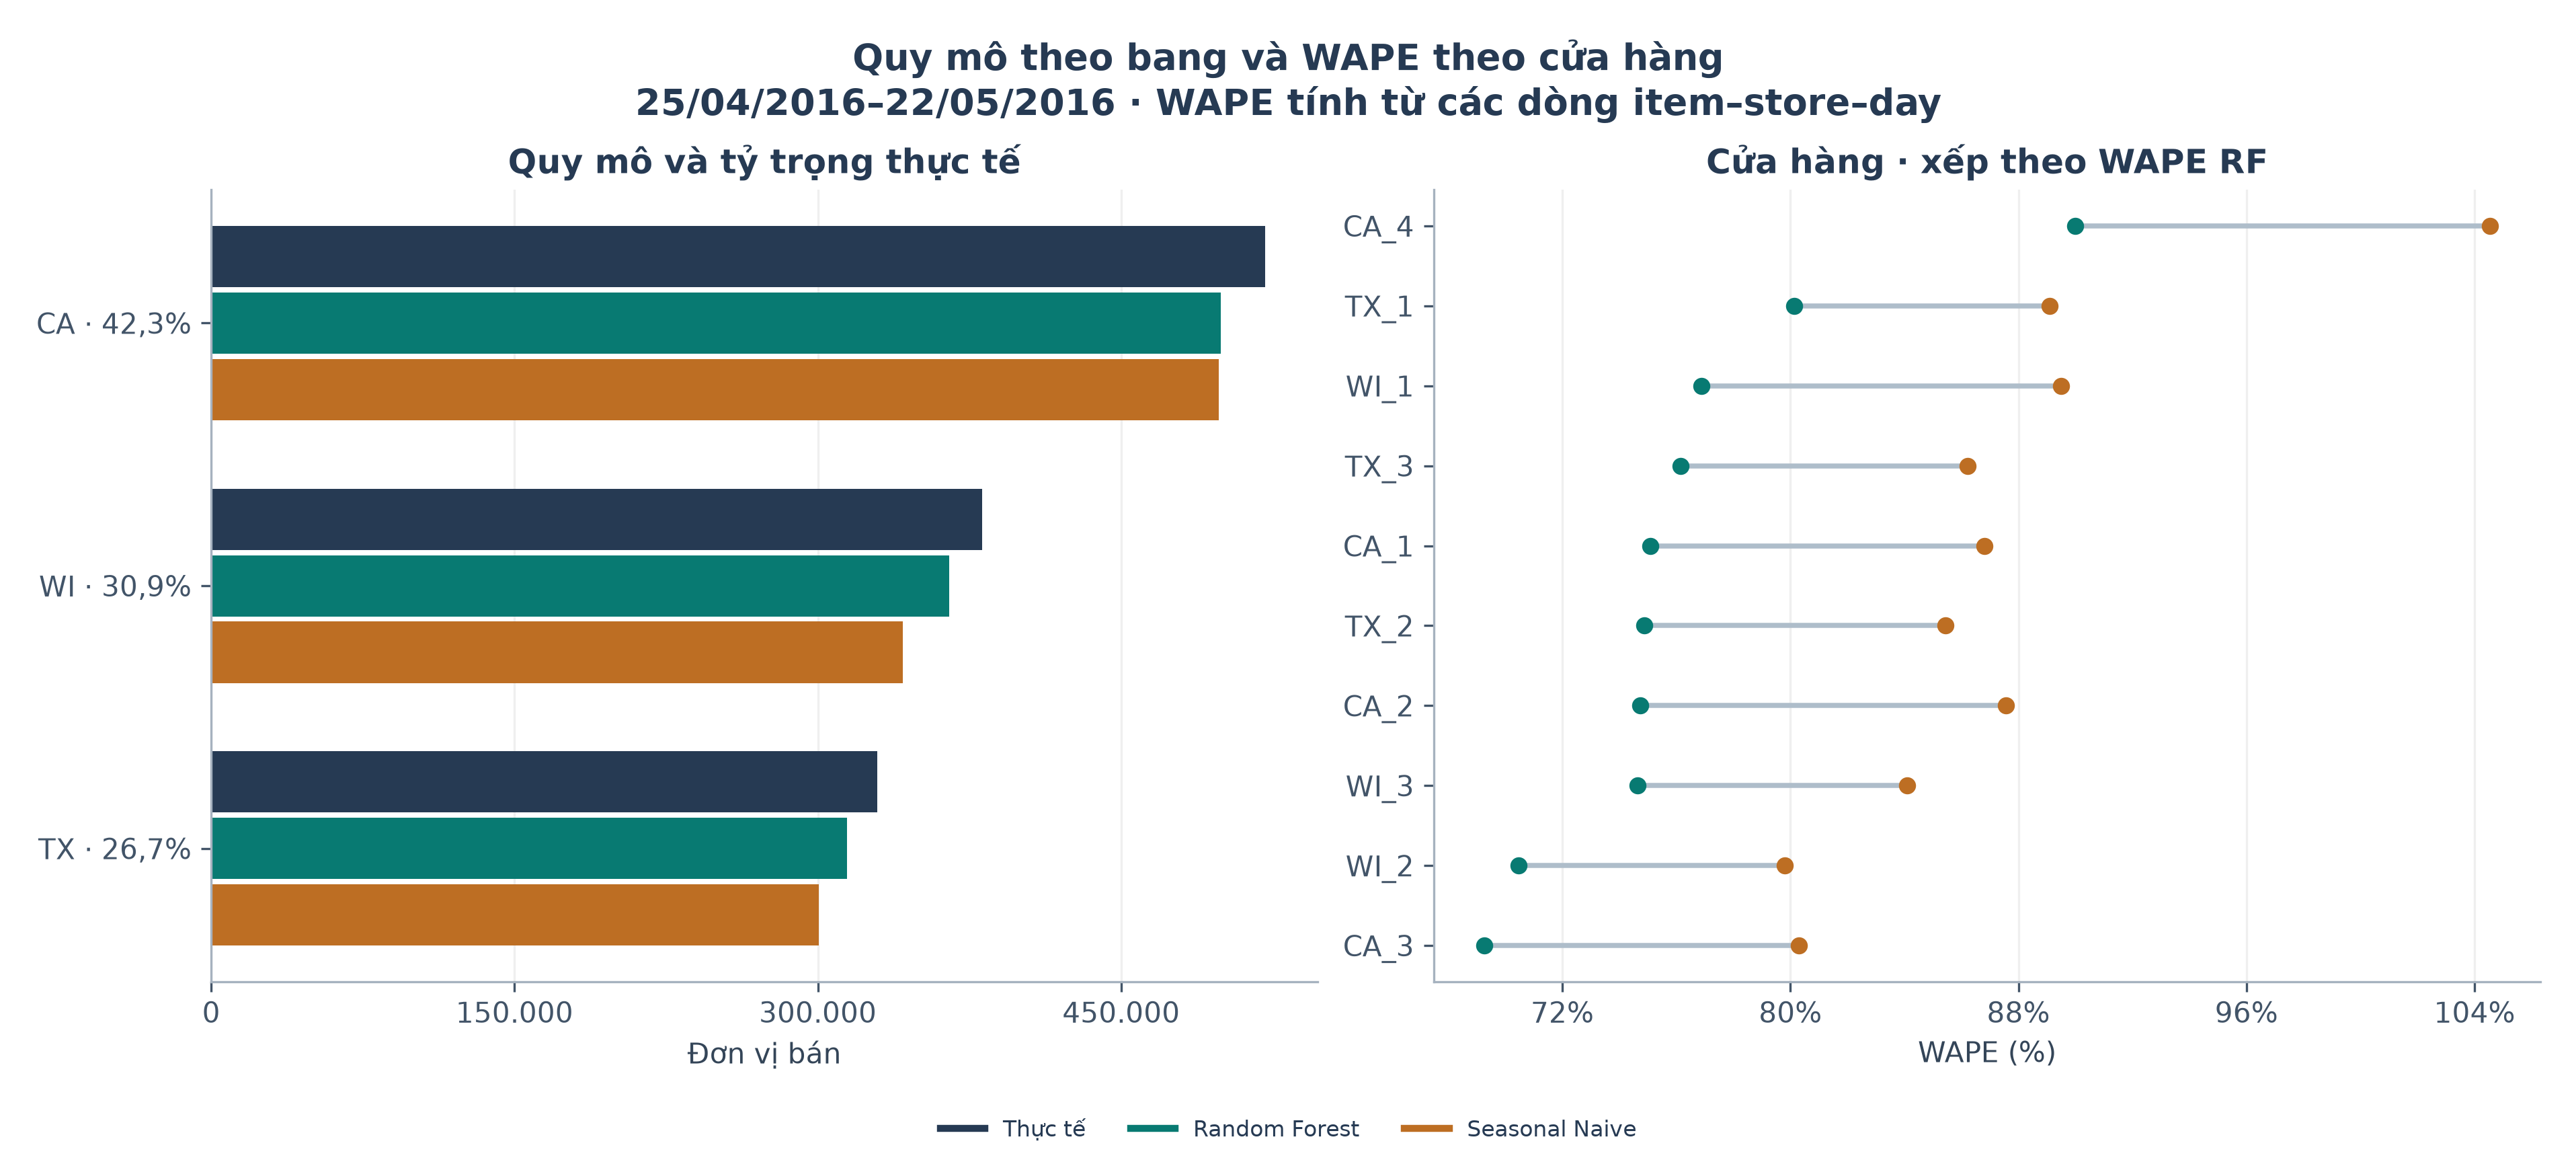

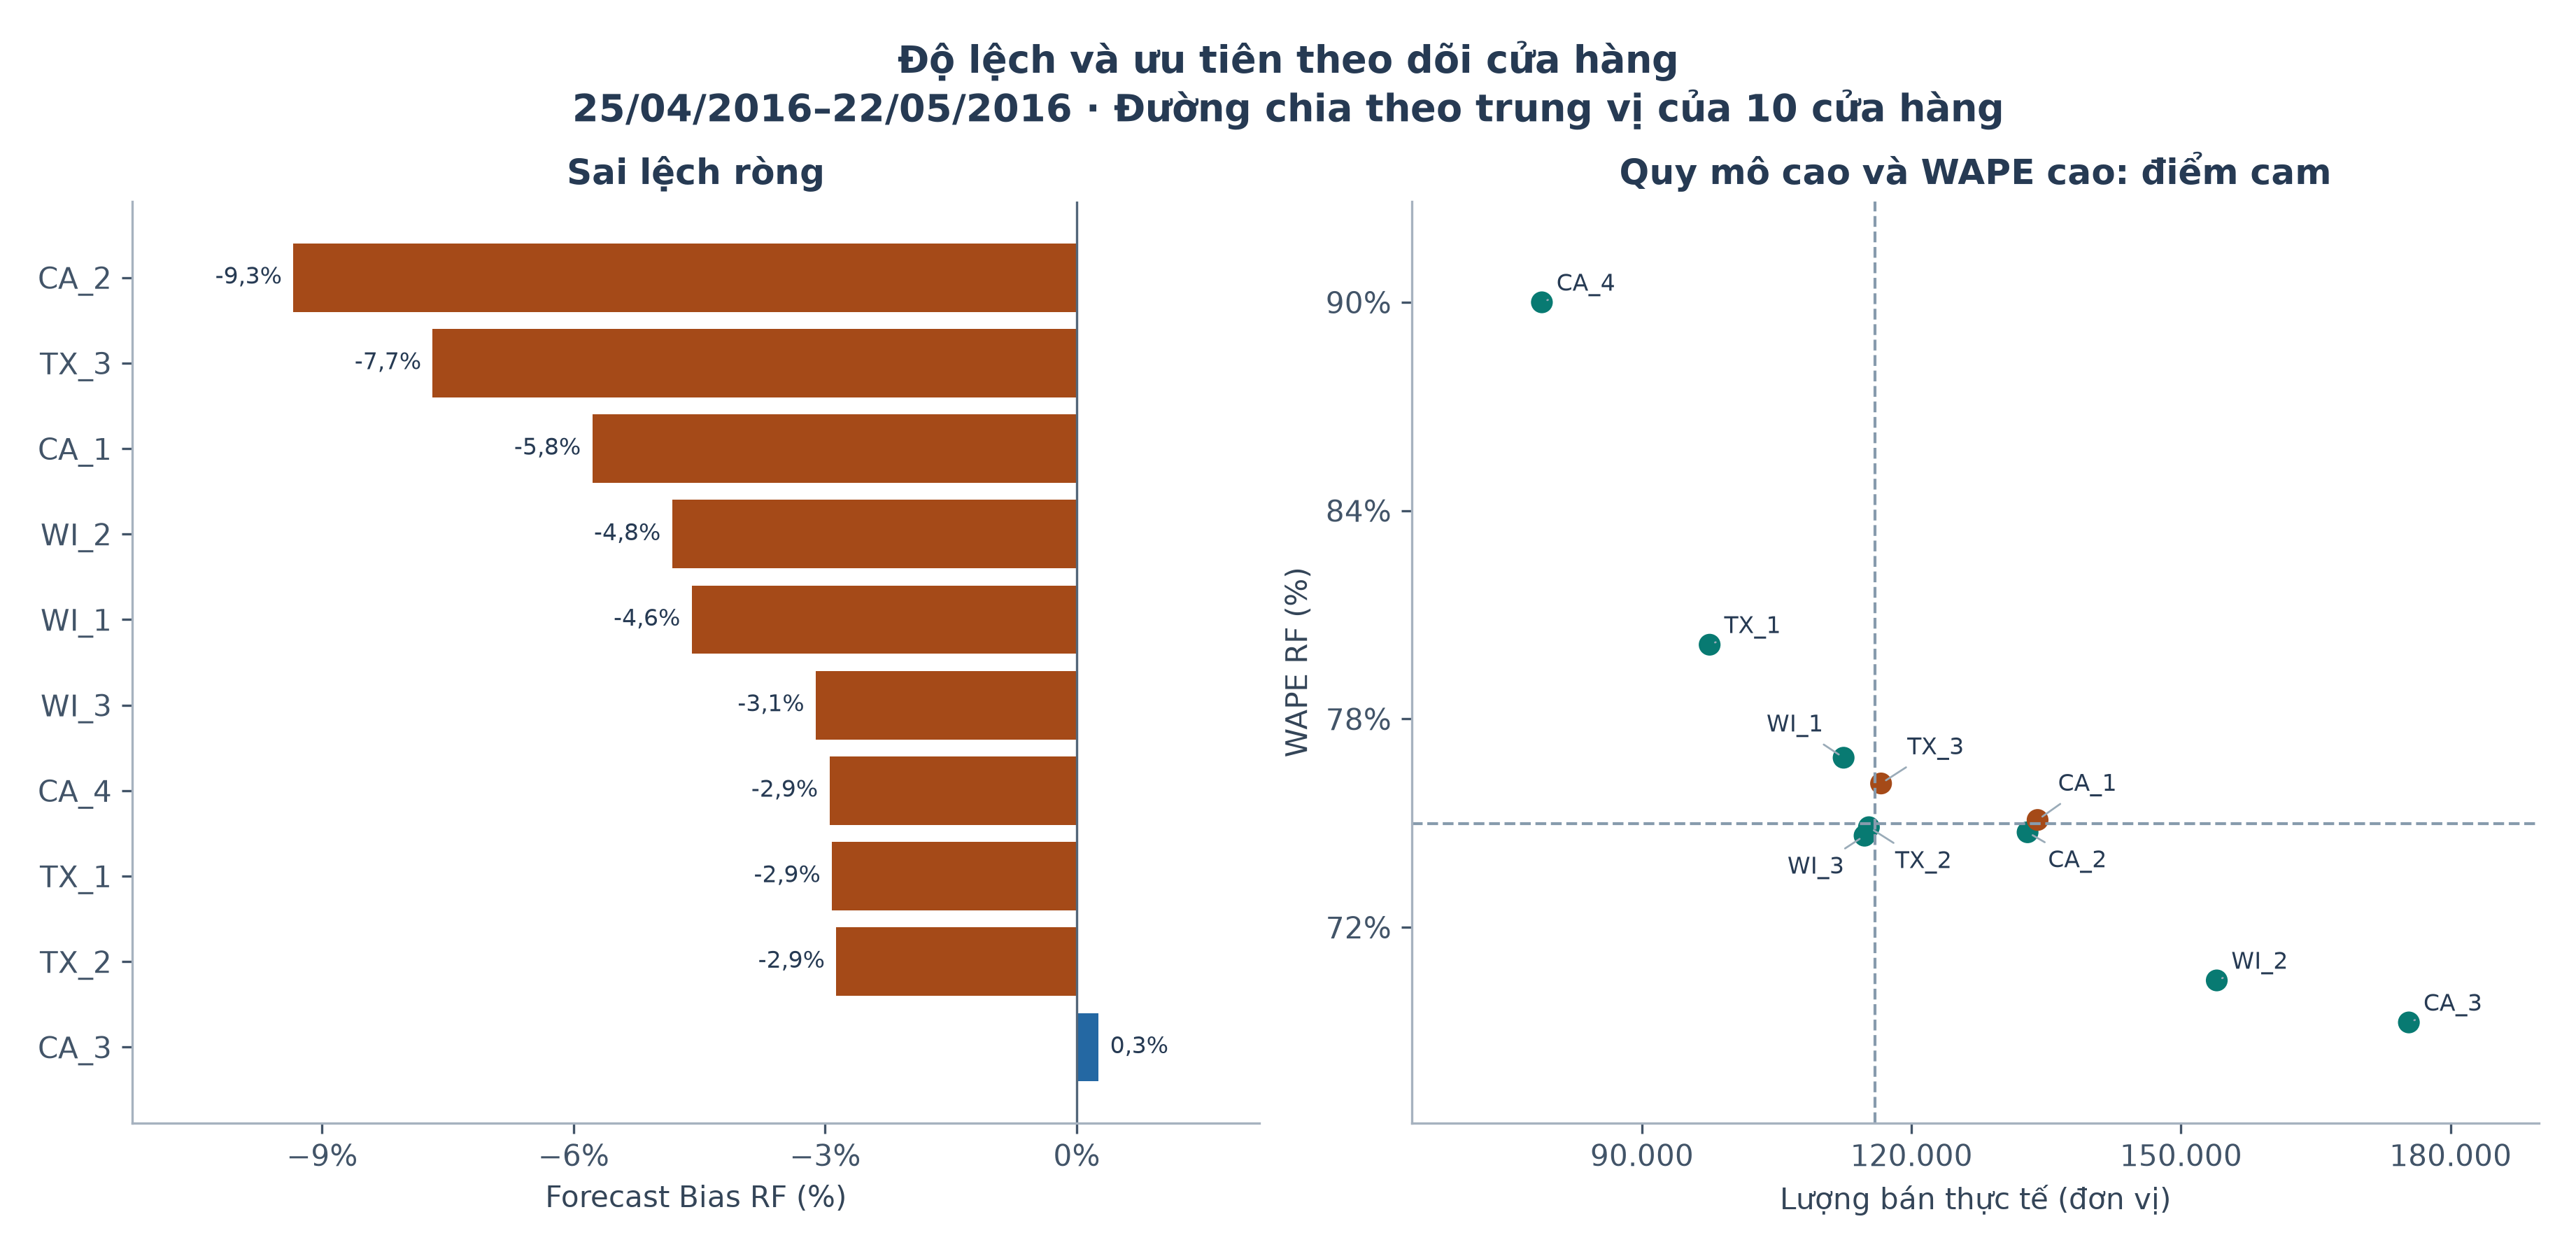

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,state_id,actual_sales,rf_error,sn_error,rf_wape_pct,rf_bias_pct
0,CA,521170,-22034.4865,-22818.0,75.2929,-4.2279
1,TX,329399,-15108.8976,-28779.0,76.8832,-4.5868
2,WI,381195,-16165.8810,-39051.0,73.6154,-4.2408


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,store_id,actual_sales,rf_error,rf_wape_pct,sn_wape_pct,rf_bias_pct,quadrant
0,CA_1,134032,-7743.9376,75.0897,86.8017,-5.7777,Cao / cao
1,CA_2,132920,-12418.3802,74.7352,87.5700,-9.3427,Cao / thấp
2,CA_3,175360,453.6967,69.2583,80.3114,0.2587,Cao / thấp
3,CA_4,78858,-2325.8654,89.9981,104.5449,-2.9494,Thấp / cao
4,TX_1,97531,-2846.9281,80.1368,89.1071,-2.9190,Thấp / cao
5,TX_2,115258,-3305.4649,74.8810,85.4518,-2.8679,Thấp / thấp
6,TX_3,116610,-8956.5046,76.1408,86.2276,-7.6807,Cao / cao
7,WI_1,112444,-5163.1041,76.8821,89.4917,-4.5917,Thấp / cao
8,WI_2,153976,-7430.5351,70.4686,79.8072,-4.8258,Cao / thấp
9,WI_3,114775,-3572.2418,74.6365,84.1028,-3.1124,Thấp / thấp


In [5]:
figure('business_v2_regional.png')
figure('business_v2_store_priority.png')
show('state_analysis', ['state_id', 'actual_sales', 'rf_error', 'sn_error', 'rf_wape_pct', 'rf_bias_pct'], 3)
show('business_v2_store_priority', ['store_id', 'actual_sales', 'rf_error', 'rf_wape_pct', 'sn_wape_pct', 'rf_bias_pct', 'quadrant'], 10)

## 6. Ngành hàng và bộ phận

**Câu hỏi.** Ngành nào chi phối tổng lượng và bộ phận nào có ngoại lệ?

- FOODS chiếm **67,59%** thực tế, với lệch RF **-48.337** đơn vị.
- **HOBBIES_2** có WAPE RF **141,65%** so với **139,02%** của SN.
- Ô cao nhất theo WAPE là **CA_4 × HOBBIES_2** (**197,15%**, 608 đơn vị thực tế). Ô Bias âm nhất là **WI_3 × FOODS_1** (**-22,22%**).

**Ứng dụng.** Xem quy mô thực tế và sai số tuyệt đối cùng tỷ lệ, nhất là các tổ hợp có lượng bán ít.

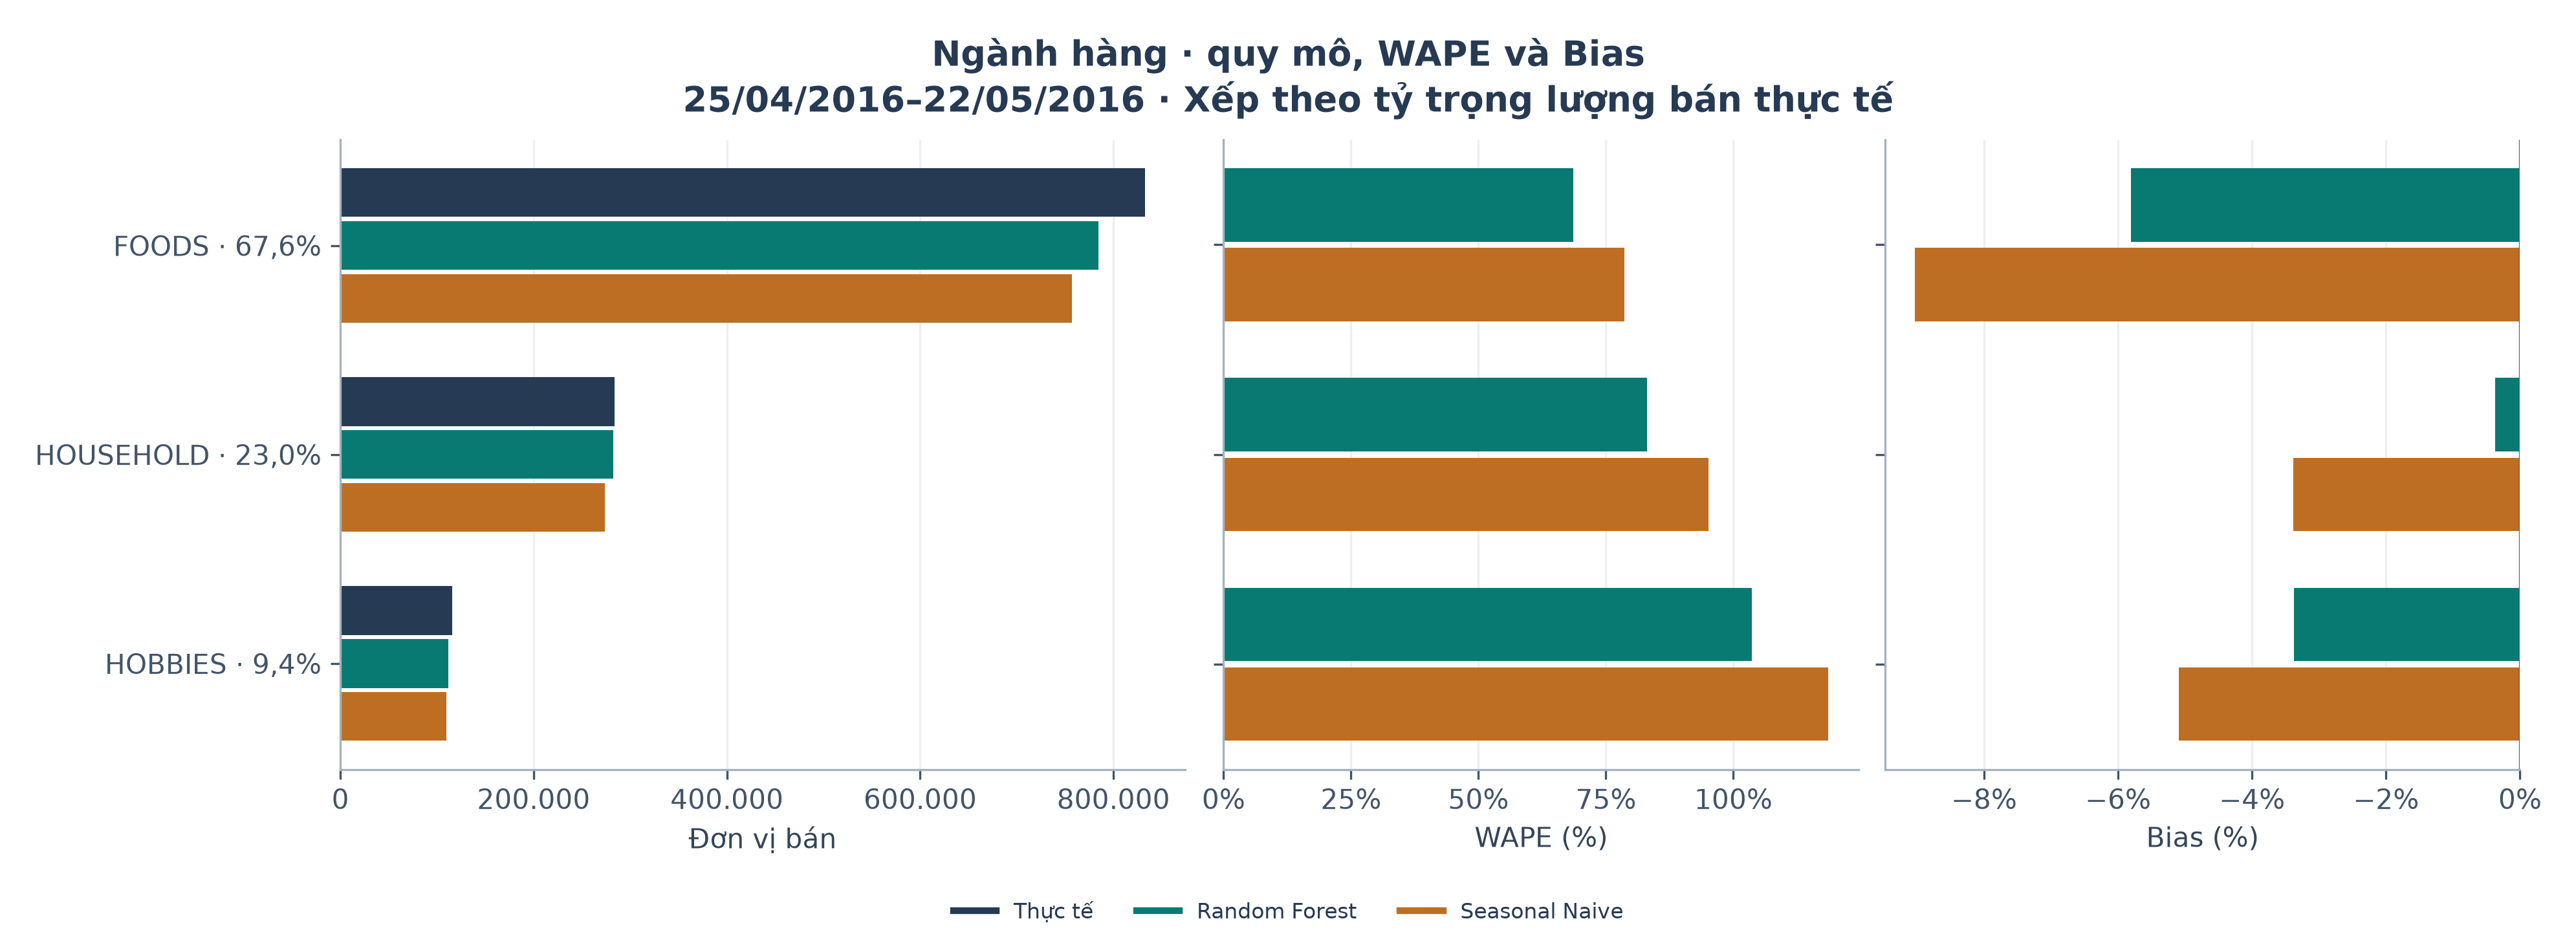

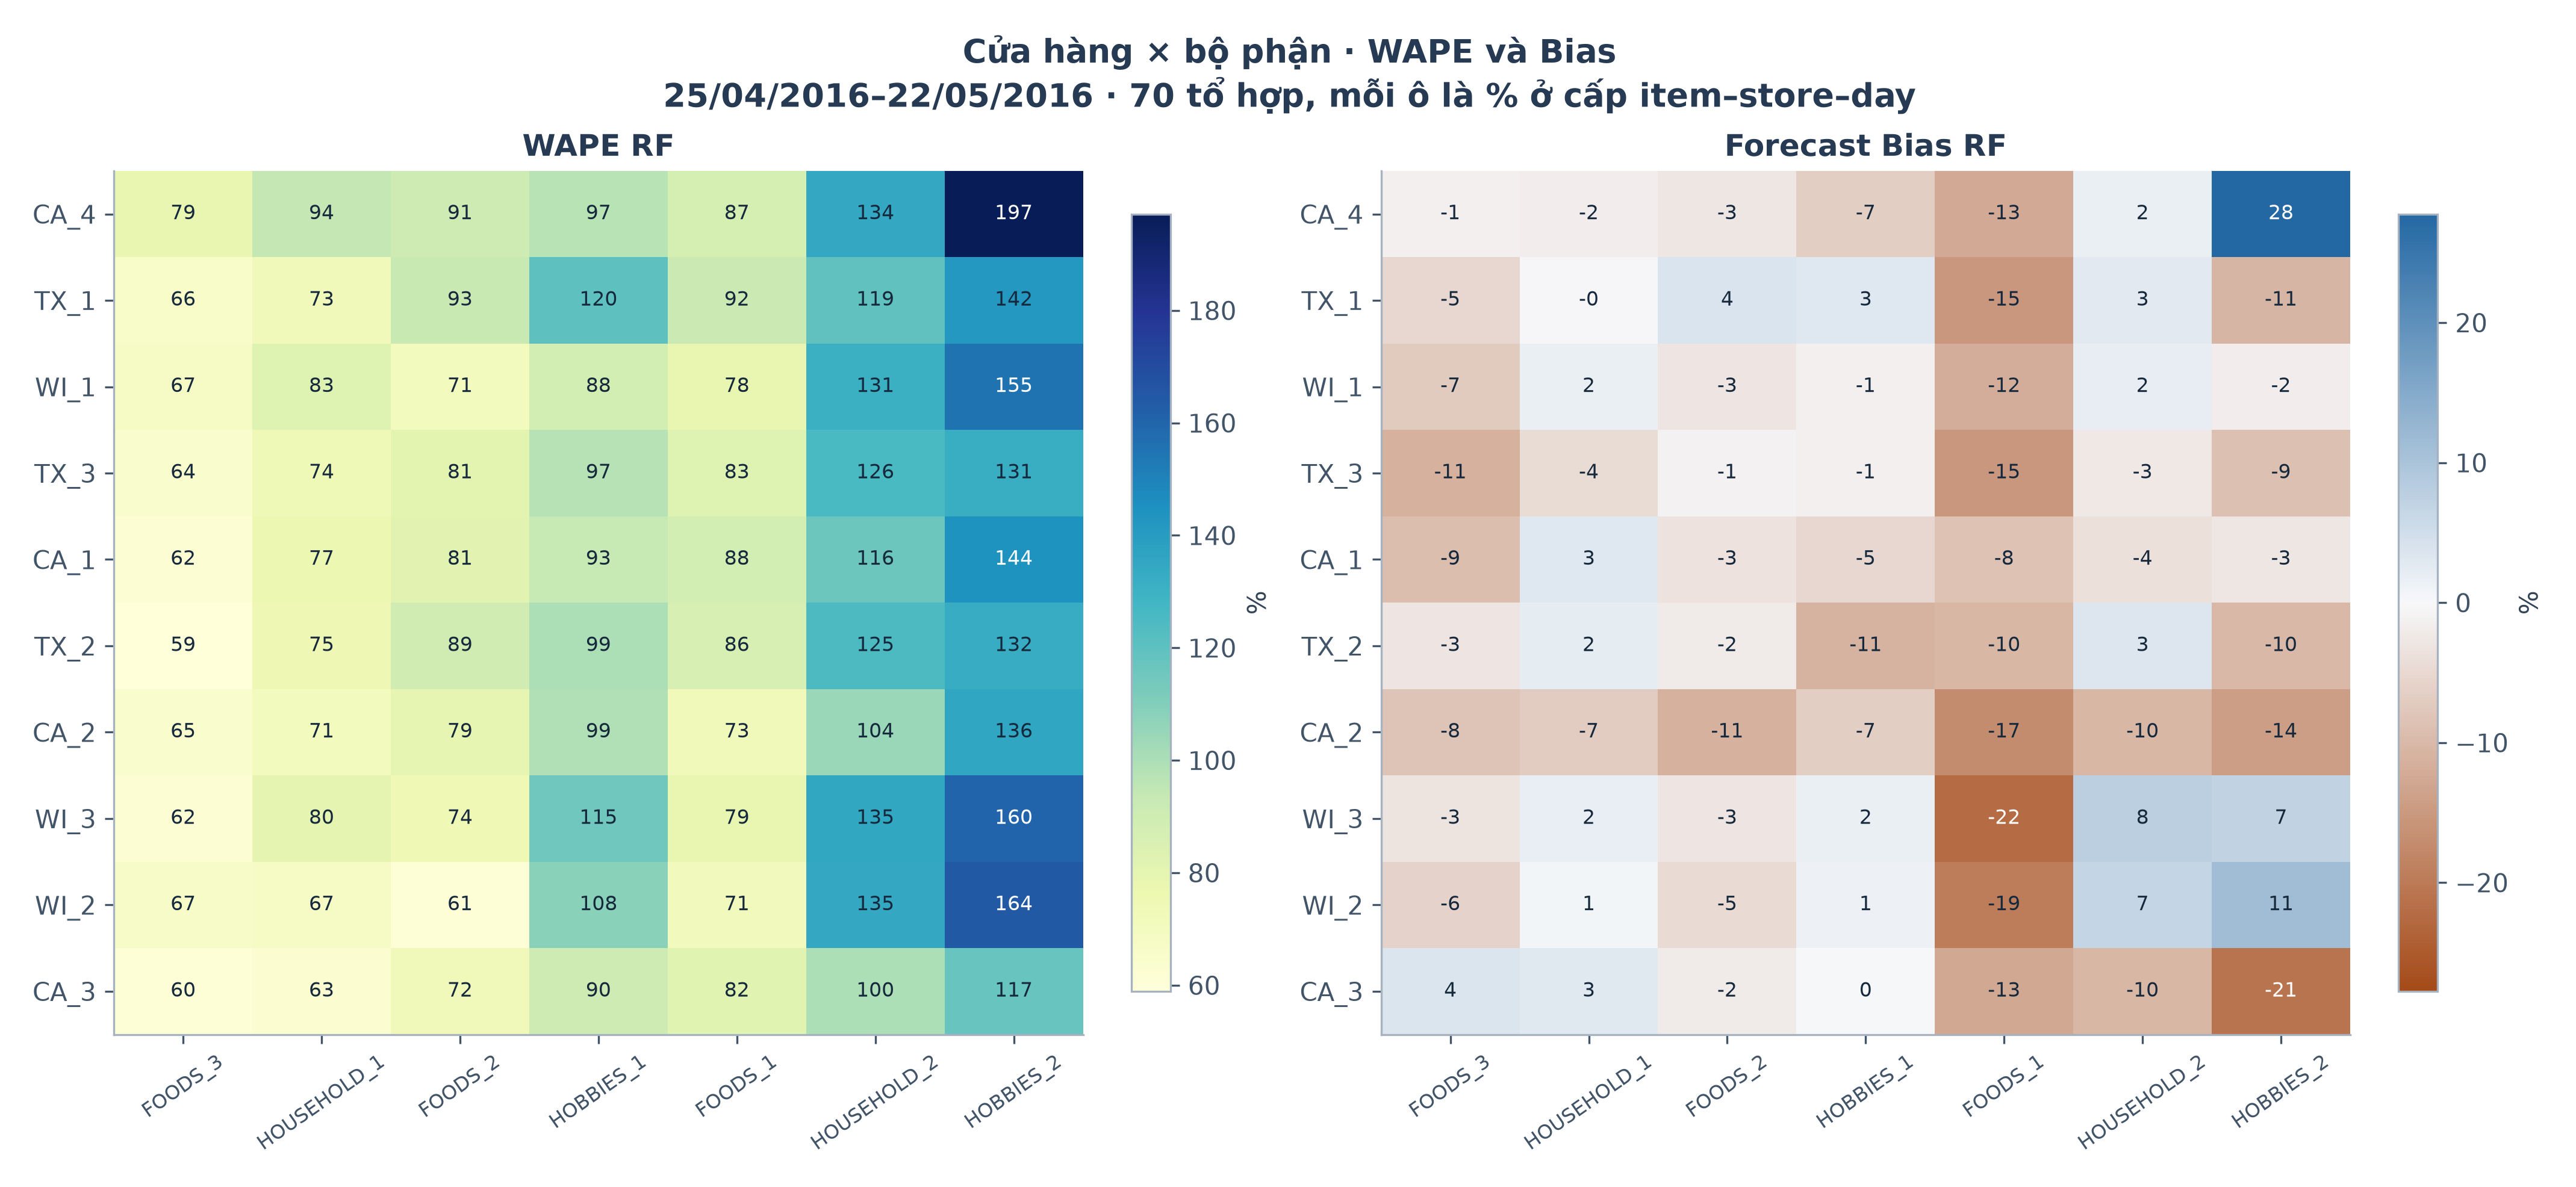

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,dept_id,actual_sales,rf_error,rf_wape_pct,sn_wape_pct,rf_bias_pct
0,FOODS_1,102359,-15139.0352,80.6895,93.0539,-14.7901
1,FOODS_2,165203,-5521.7266,75.7973,89.6297,-3.3424
2,FOODS_3,564926,-27676.6648,64.2441,72.8524,-4.8992
3,HOBBIES_1,102554,-3104.7632,98.6836,116.0033,-3.0274
4,HOBBIES_2,13302,-802.5042,141.6541,139.0167,-6.0330
5,HOUSEHOLD_1,222327,210.4200,73.3360,86.2923,0.0946
6,HOUSEHOLD_2,61093,-1274.9911,118.5702,127.3681,-2.0870


In [6]:
figure('business_v2_category.png')
figure('business_v2_heatmaps.png')
show('department_analysis', ['dept_id', 'actual_sales', 'rf_error', 'rf_wape_pct', 'sn_wape_pct', 'rf_bias_pct'], 7)

## 7. Sản phẩm và danh mục ABC

**Câu hỏi.** Sai số tập trung ở đâu và có thể phân nhóm từ lịch sử ra sao?

- **5.704**, **15.714**, **21.063** chuỗi đầu tiên tạo ít nhất 50%, 80% và 90% sai số tuyệt đối RF. Mốc 80% tương ứng **51,54%** số chuỗi.
- Top 15 contribution chiếm **3,82%** contribution cấp 12, theo RMSSE nhân trọng số doanh thu lịch sử.
- Phân vị của chuỗi có bán lịch sử là **11,0** và **31,0** đơn vị. WAPE RF của nhóm chưa bán trong 28 ngày lịch sử là **119,06%**, của nhóm cao là **59,53%**.
- ABC A gồm **10.715** chuỗi và **80,00%** tỷ trọng doanh thu lịch sử. WAPE RF của A là **58,96%**. Ở C, WAPE RF **135,83%** cao hơn SN **125,40%**.

**Ứng dụng.** Ưu tiên chuỗi doanh thu lịch sử cao hoặc contribution lớn. Giữ danh sách Pareto riêng khi mục tiêu là giảm tổng sai số đơn vị.

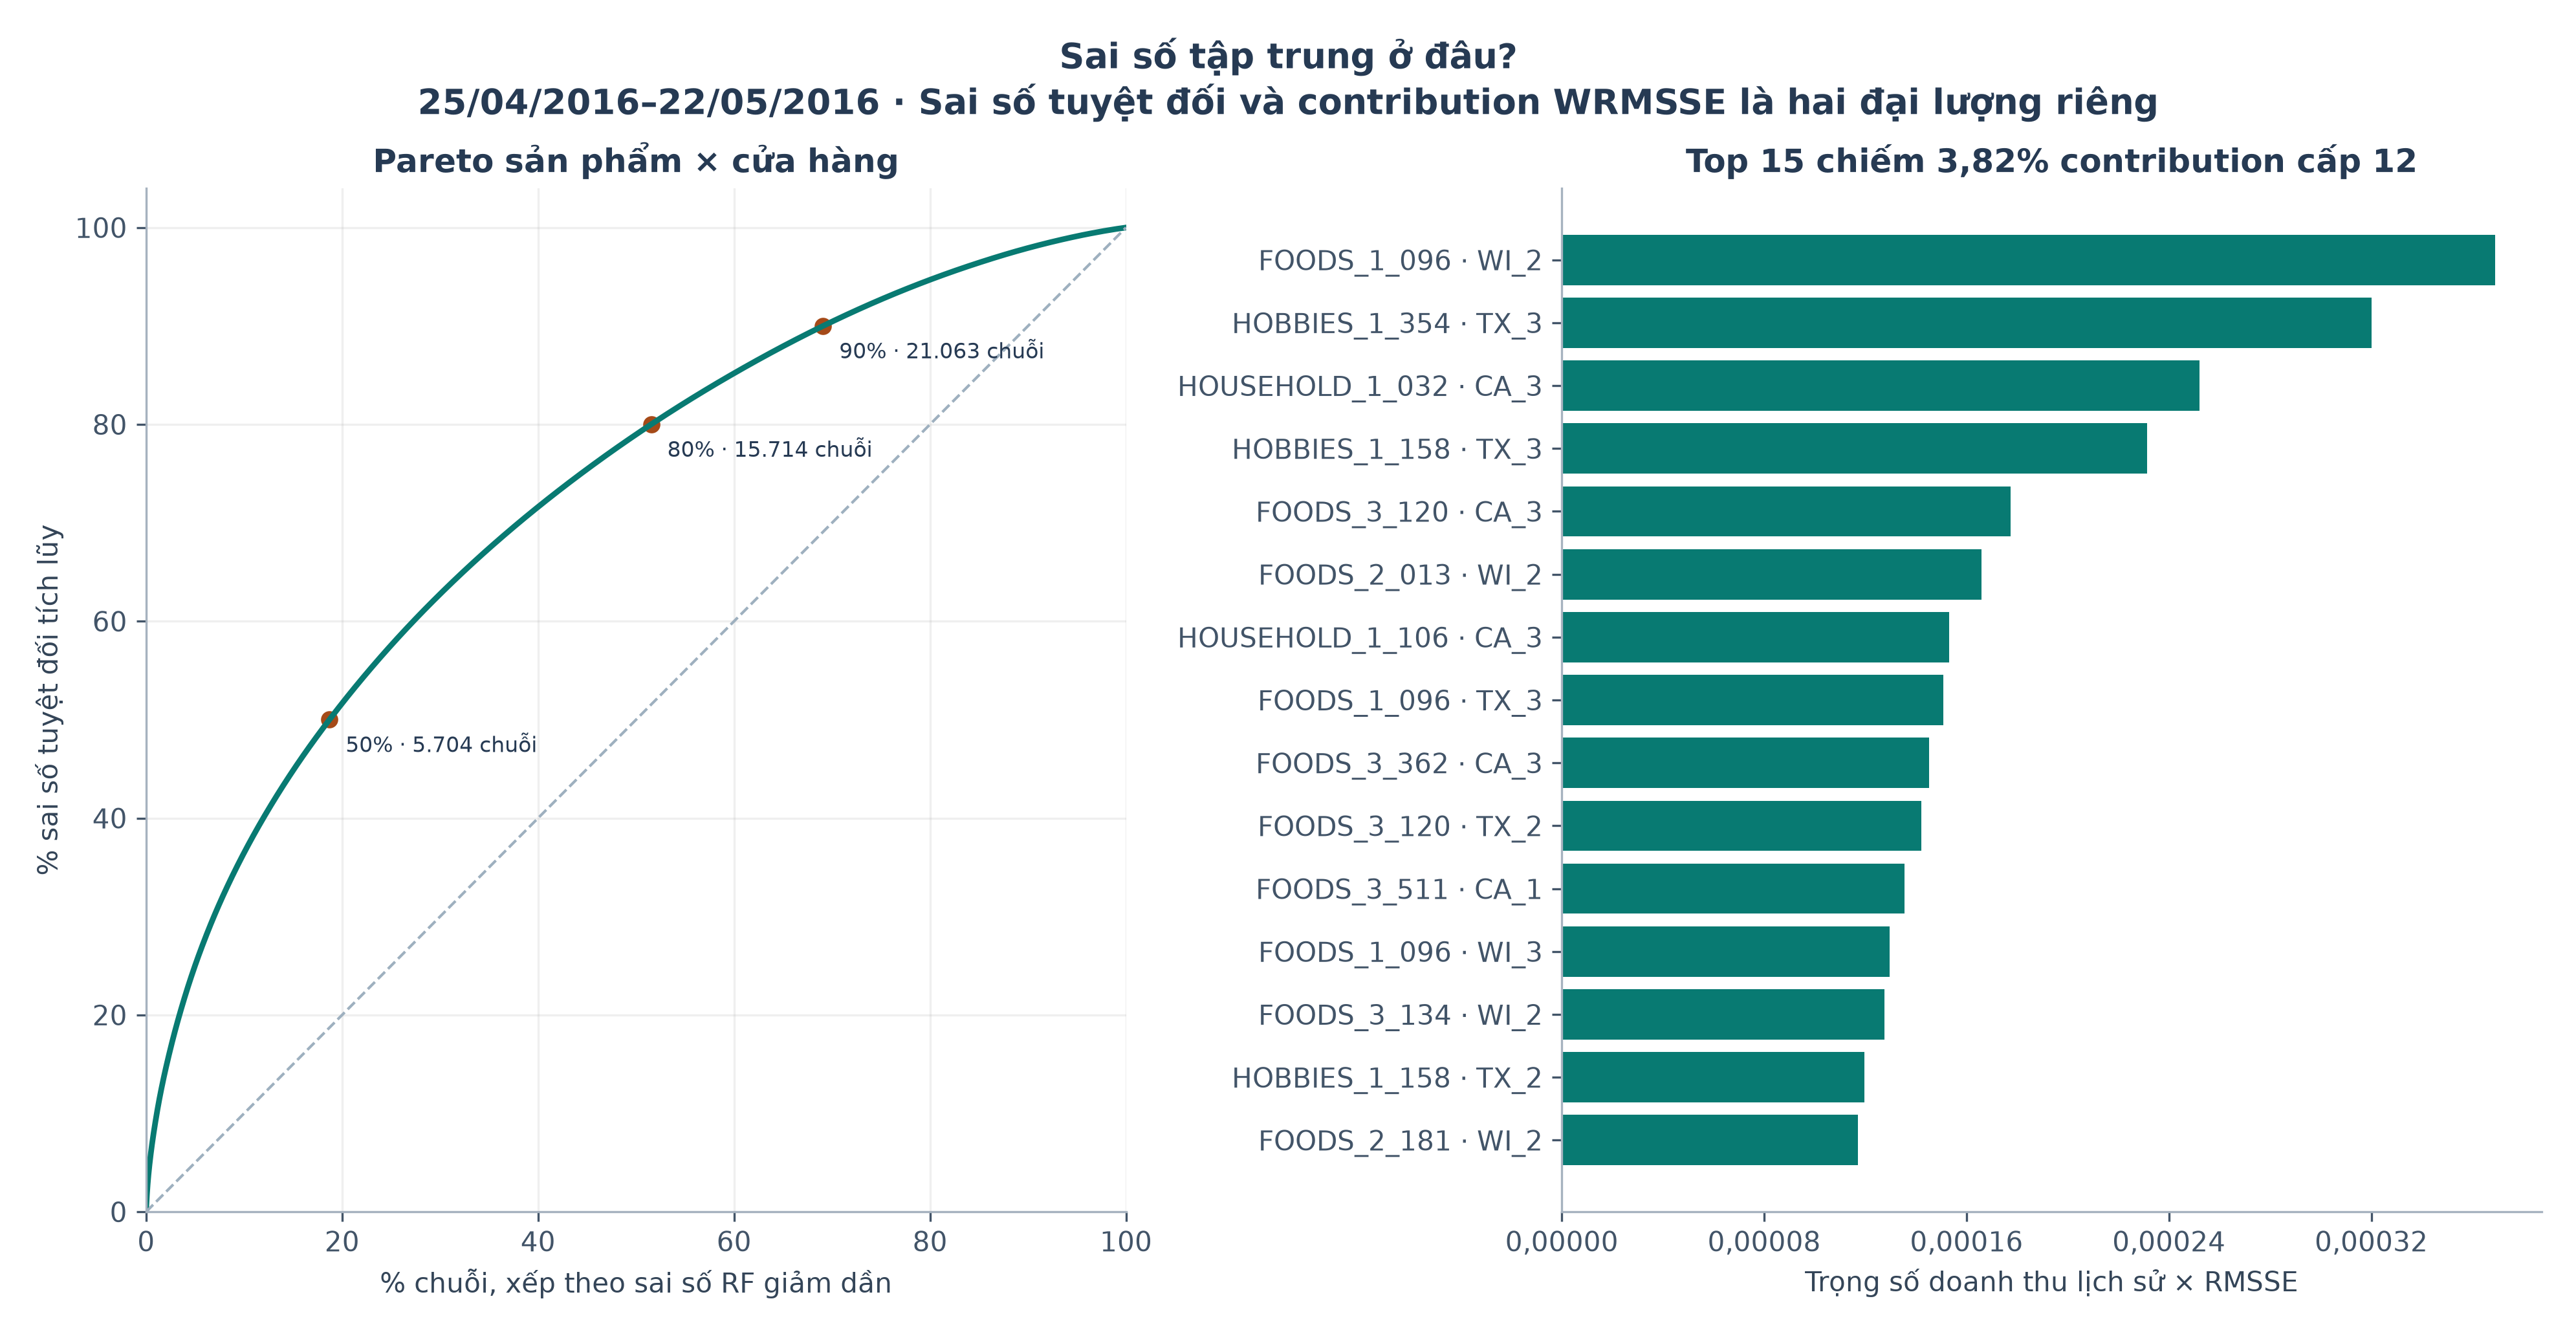

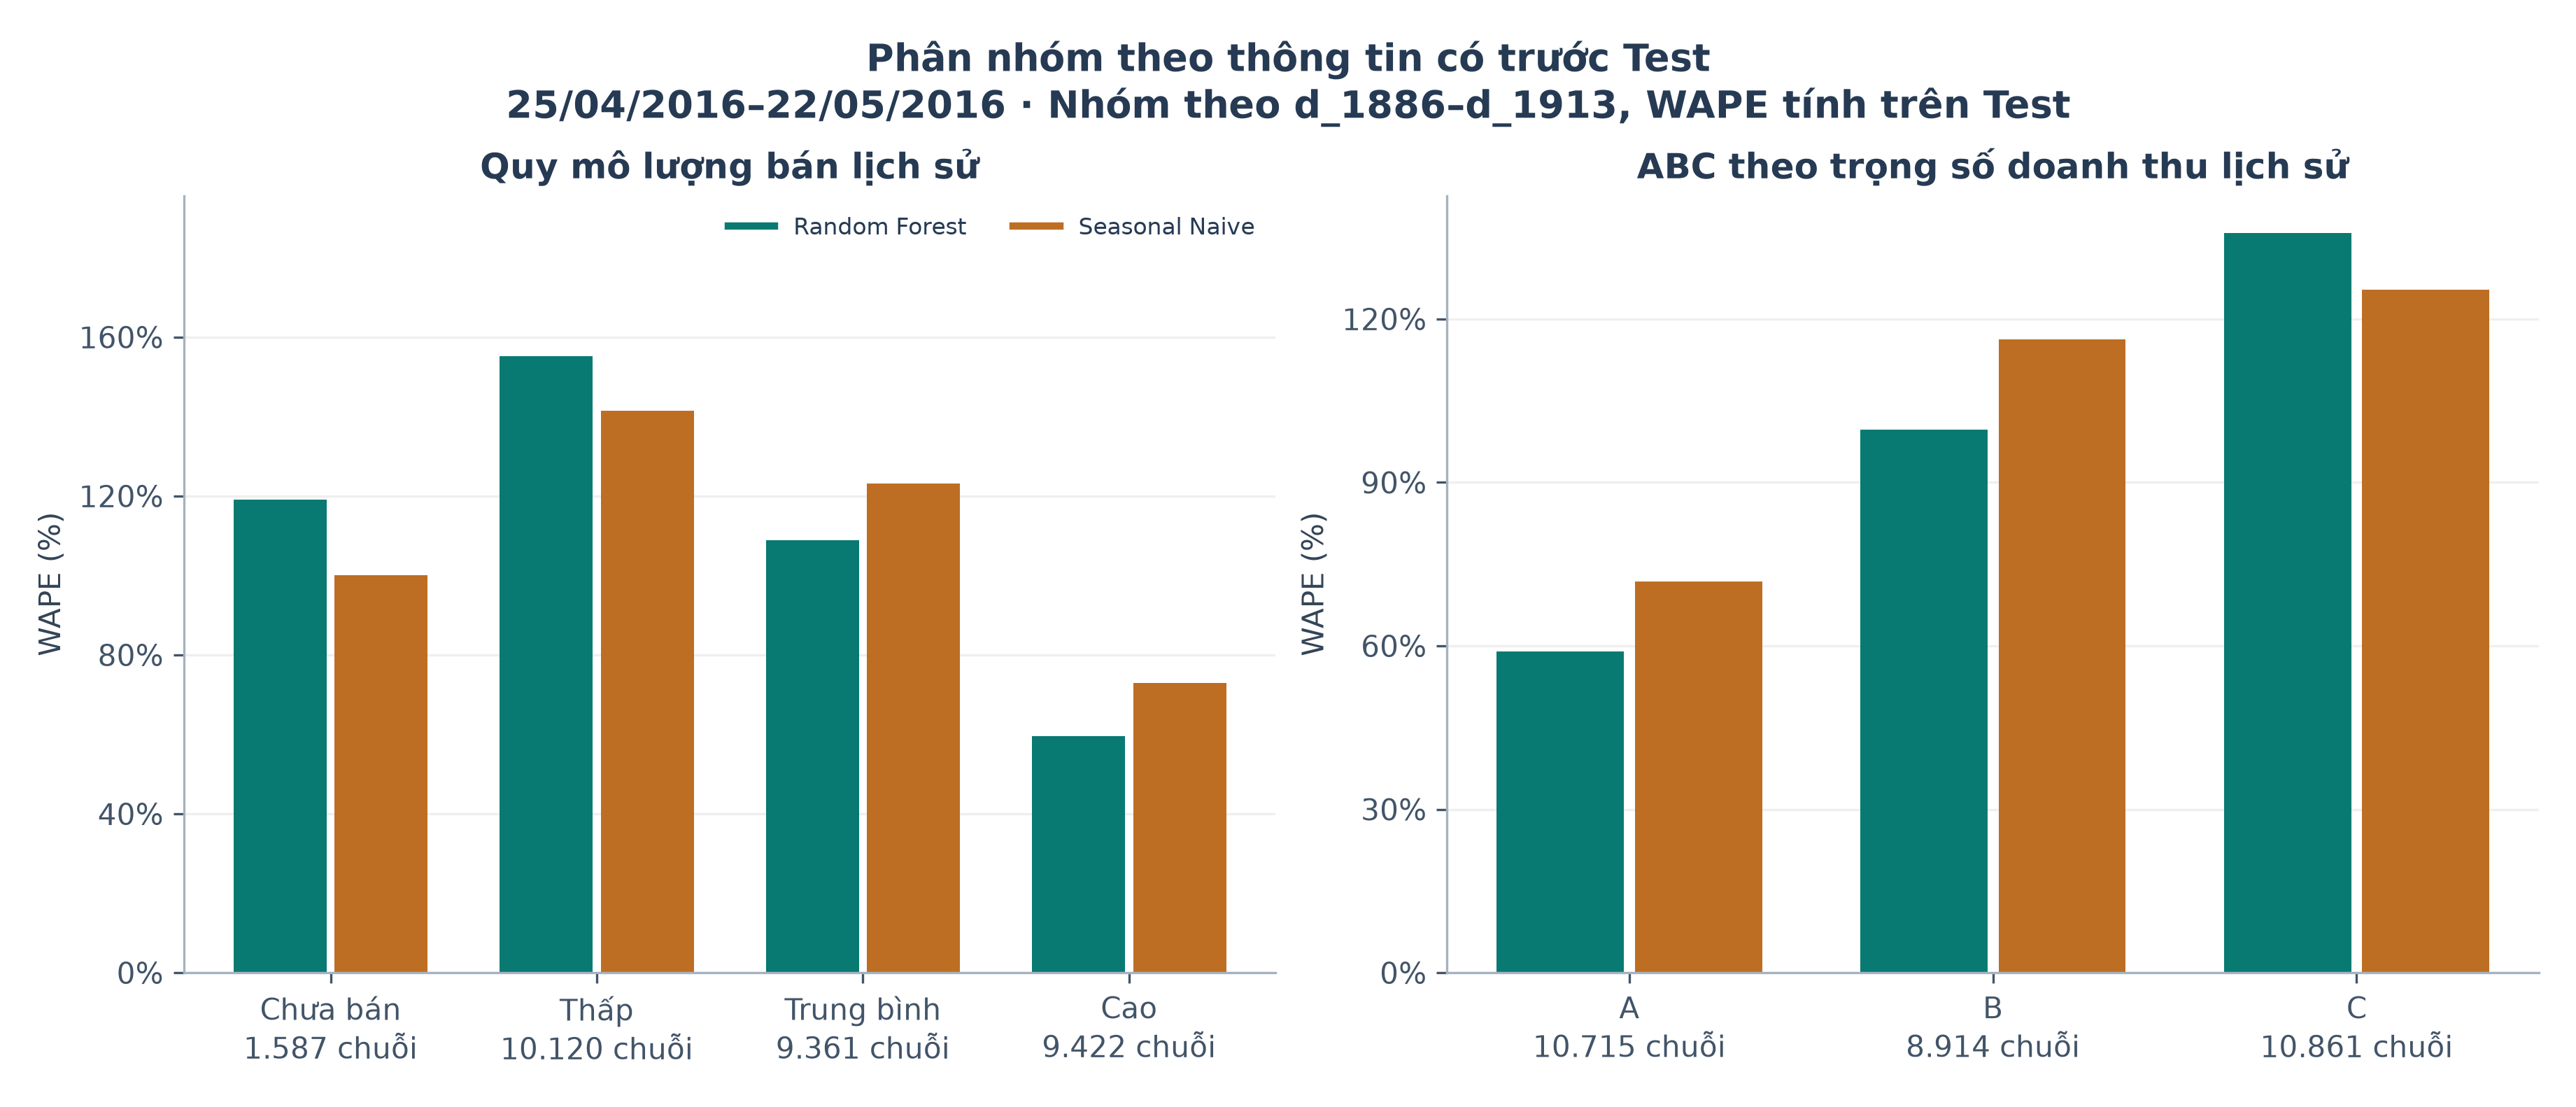

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,target_pct,rank,series_pct,cumulative_error_pct
0,50,5704,18.7078,50.0005
1,80,15714,51.5382,80.0019
2,90,21063,69.0817,90.0005


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,volume,n_series,actual_sales,rf_wape_pct,sn_wape_pct,rf_mae,sn_mae,wape_pct_improvement_pct
0,0 · Chưa bán,1587,29983,119.0641,100.0000,0.8034,0.6747,-19.0641
1,1 · Thấp,10120,81417,155.2271,141.4066,0.4460,0.4063,-9.7736
2,2 · Trung bình,9361,196971,108.8954,123.1862,0.8183,0.9257,11.6010
3,3 · Cao,9422,923393,59.5307,73.0189,2.0837,2.5558,18.4722


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,abc,n_series,historical_revenue_share,actual_sales,rf_wape_pct,sn_wape_pct,rf_bias_pct,sn_bias_pct,wape_pct_improvement_pct
0,A,10715,0.80,862289,58.9627,71.8753,-3.2556,-2.5232,17.9653
1,B,8914,0.15,232147,99.6421,116.3172,-4.4779,-5.3134,14.3359
2,C,10861,0.05,137328,135.8279,125.3961,-10.8075,-41.1832,-8.3190


In [7]:
figure('business_v2_concentration.png')
figure('business_v2_segments.png')
show('business_v2_pareto_thresholds', ['target_pct', 'rank', 'series_pct', 'cumulative_error_pct'], 3)
show('business_v2_volume_segments', ['volume', 'n_series', 'actual_sales', 'rf_wape_pct', 'sn_wape_pct', 'rf_mae', 'sn_mae', 'wape_pct_improvement_pct'], 4)
show('business_v2_abc', ['abc', 'n_series', 'historical_revenue_share', 'actual_sales', 'rf_wape_pct', 'sn_wape_pct', 'rf_bias_pct', 'sn_bias_pct', 'wape_pct_improvement_pct'], 3)

## 8. Ngoại lệ cấp chuỗi

**Câu hỏi.** Sai lệch lớn nhất về số lượng nằm ở chuỗi nào?

- RF thiếu nhiều nhất ở **FOODS_3_234 × WI_2** (**-988** đơn vị), và thừa nhiều nhất ở **FOODS_3_362 × CA_3** (**+694** đơn vị).
- Ví dụ bán gián đoạn **HOBBIES_2_124 × WI_2** có **27** ngày không bán trong 28 ngày. Panel riêng cho thấy hình dạng chuỗi trước khi so sánh WAPE.

**Ứng dụng.** Đối chiếu lịch bán, trạng thái mặt hàng và dữ liệu cửa hàng ở những chuỗi cực trị. Đây là tín hiệu kiểm tra dự báo.

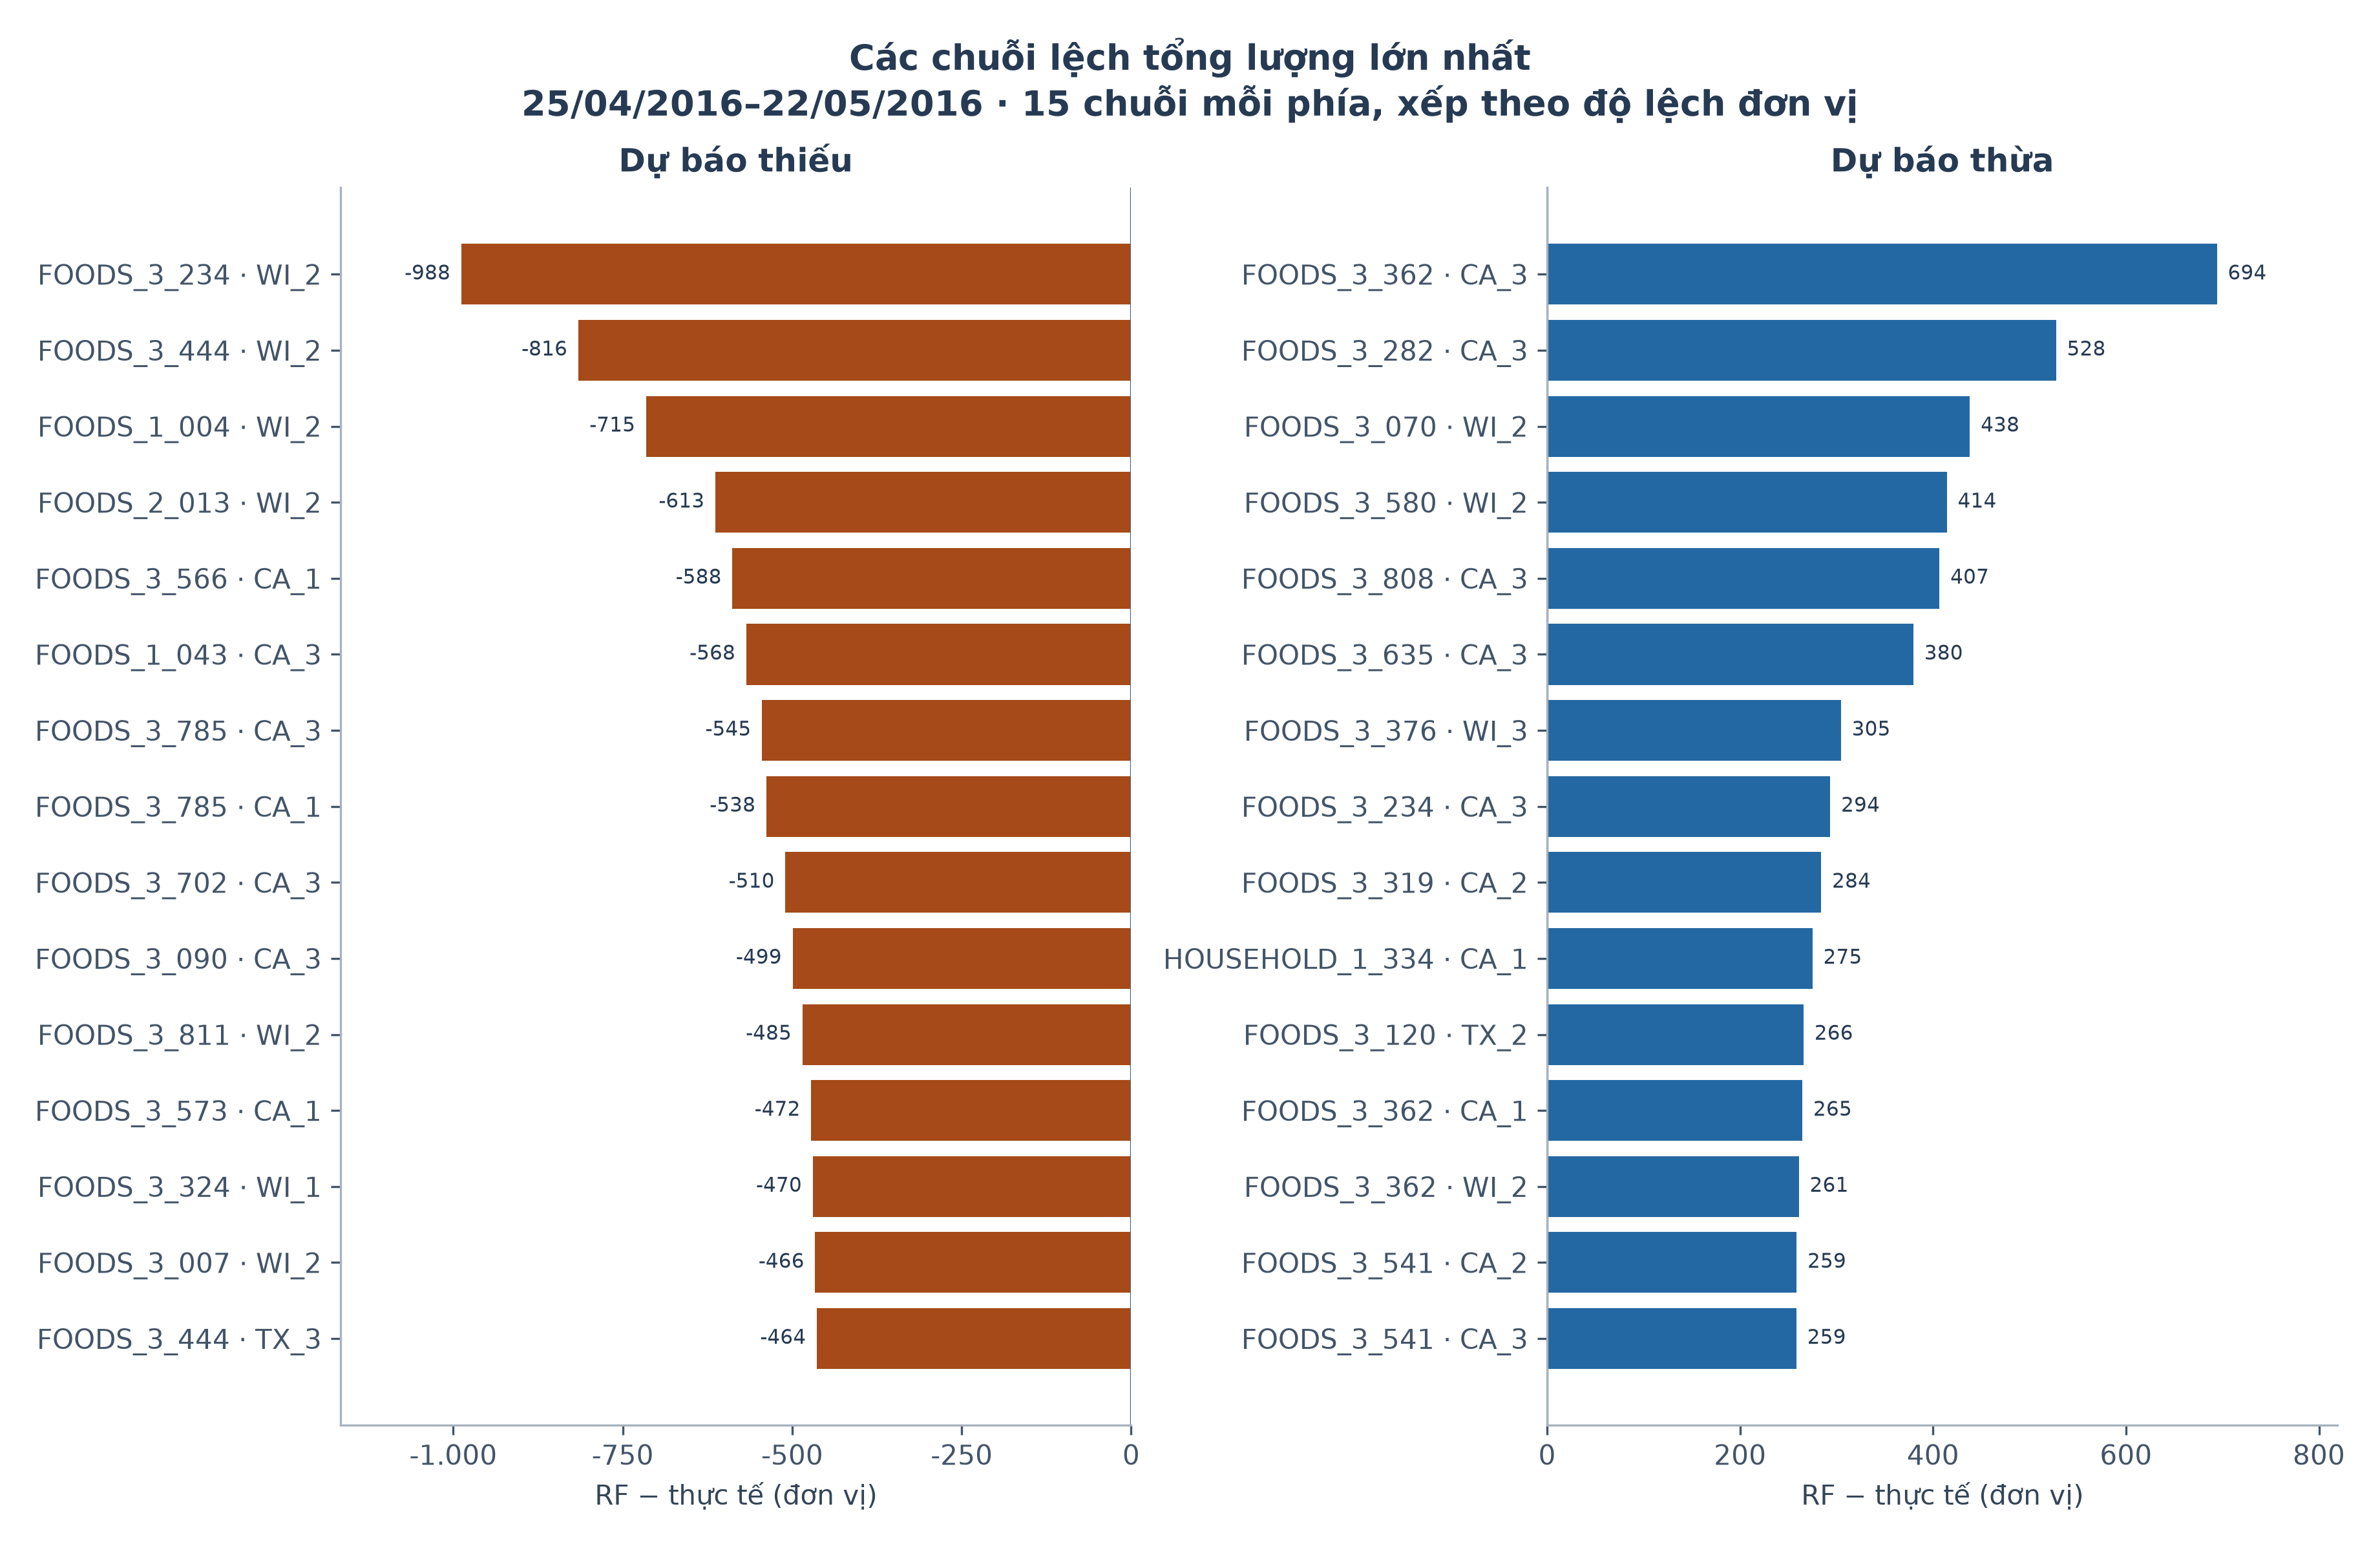

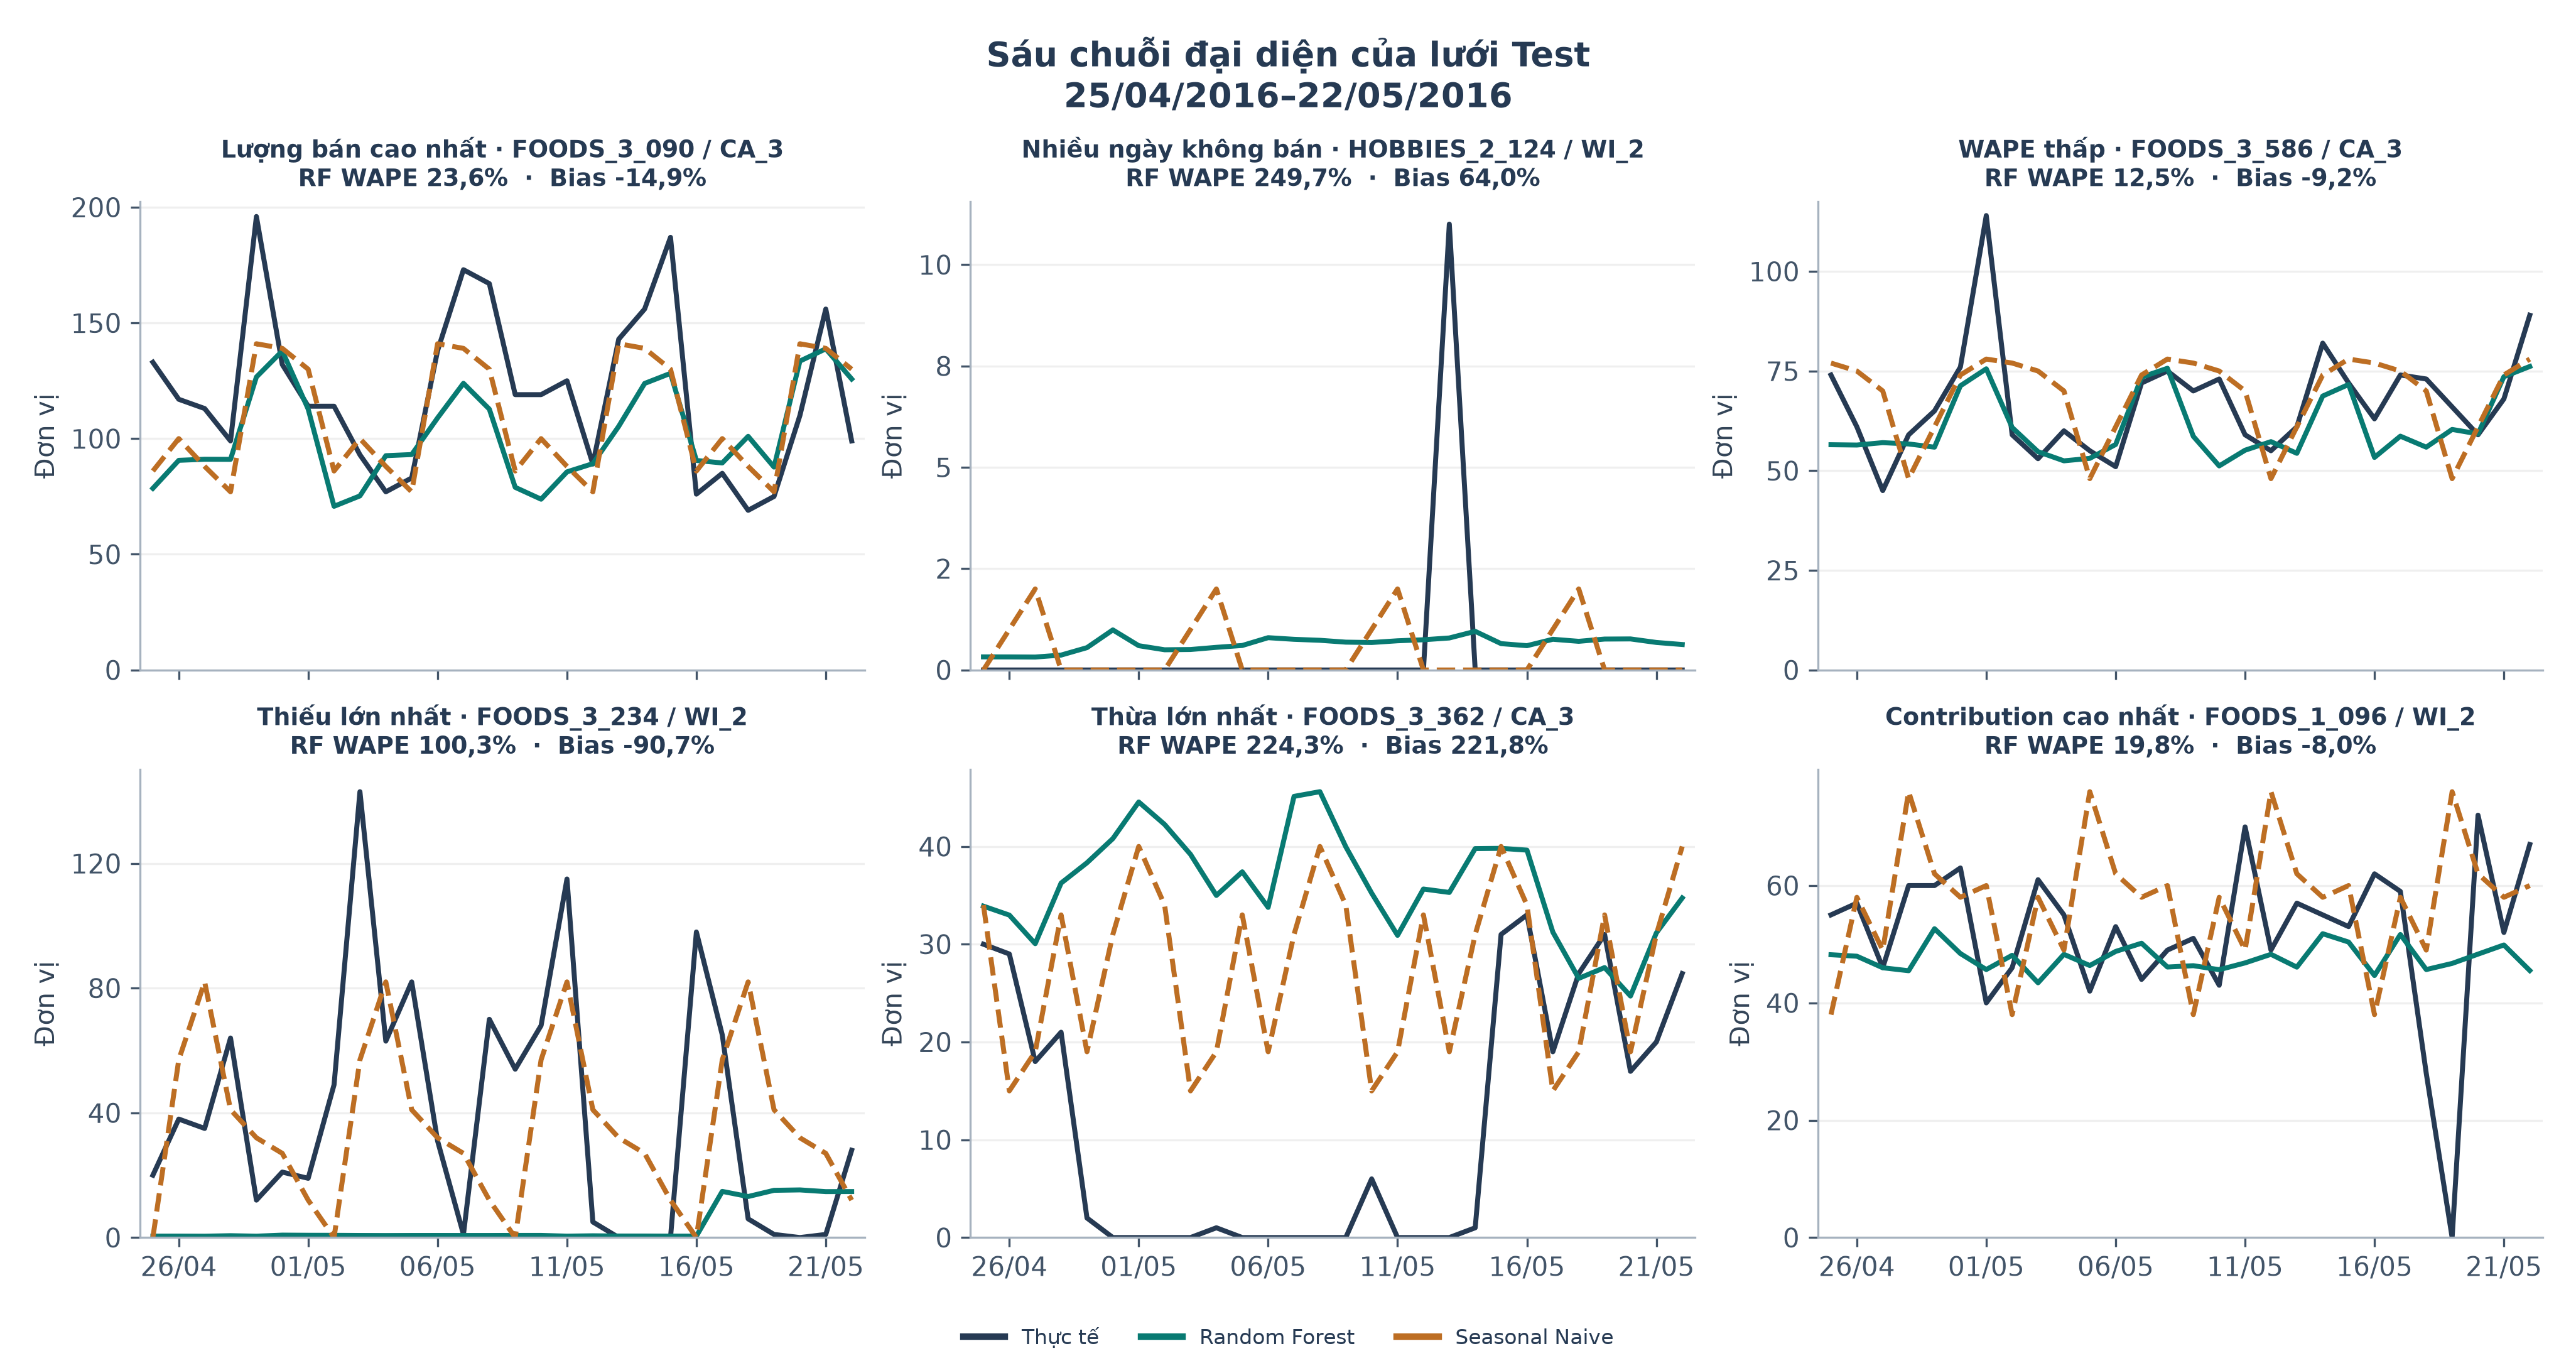

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,direction,item_id,store_id,cat_id,actual_sales,random_forest_forecast,rf_error,rf_bias_pct,rf_wape_pct
0,Thiếu,FOODS_3_234,WI_2,FOODS,1089,100.8168,-988.1832,-90.7423,100.2506
1,Thiếu,FOODS_3_444,WI_2,FOODS,855,39.3554,-815.6446,-95.3970,98.3782
2,Thiếu,FOODS_1_004,WI_2,FOODS,723,7.5428,-715.4572,-98.9567,99.1803
3,Thiếu,FOODS_2_013,WI_2,FOODS,1415,801.6448,-613.3552,-43.3467,43.3467
4,Thiếu,FOODS_3_566,CA_1,FOODS,750,161.7646,-588.2354,-78.4314,79.2308
5,Thiếu,FOODS_1_043,CA_3,FOODS,581,13.1628,-567.8372,-97.7344,98.1878
6,Thiếu,FOODS_3_785,CA_3,FOODS,608,63.4116,-544.5884,-89.5705,89.5705
7,Thiếu,FOODS_3_785,CA_1,FOODS,599,60.8157,-538.1843,-89.8471,89.8471
8,Thiếu,FOODS_3_702,CA_3,FOODS,696,185.8978,-510.1022,-73.2905,73.2905
9,Thiếu,FOODS_3_090,CA_3,FOODS,3357,2857.5616,-499.4384,-14.8775,23.5633


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,criterion,item_id,store_id,zero_actual_days,rf_wape_pct,rf_bias_pct
0,Lượng bán Test cao nhất,FOODS_3_090,CA_3,0,23.5633,-14.8775
1,"Nhiều ngày không bán, có ngày bán",HOBBIES_2_124,WI_2,27,249.6659,64.0177
2,WAPE thấp trong nhóm lượng bán ≥ trung vị dương,FOODS_3_586,CA_3,0,12.5077,-9.1683
3,Thiếu nhiều nhất,FOODS_3_234,WI_2,4,100.2506,-90.7423
4,Thừa nhiều nhất,FOODS_3_362,CA_3,12,224.3254,221.8444
5,Đóng góp WRMSSE lớn nhất,FOODS_1_096,WI_2,1,19.7678,-7.9800


In [8]:
figure('business_v2_exceptions.png')
figure('business_v2_representatives.png')
show('business_v2_exceptions', ['direction', 'item_id', 'store_id', 'cat_id', 'actual_sales', 'random_forest_forecast', 'rf_error', 'rf_bias_pct', 'rf_wape_pct'], 30)
show('business_v2_representatives', ['criterion', 'item_id', 'store_id', 'zero_actual_days', 'rf_wape_pct', 'rf_bias_pct'], 6)

## 9. Sai số và độ ổn định

**Câu hỏi.** Lợi thế RF có xuất hiện nhất quán ở từng chuỗi và từng kiểu ngày bán?

- RF có MAE thấp hơn ở **18.161** chuỗi (**59,56%**); tương đương **15**; SN thấp hơn **12.314**. Tolerance tuyệt đối **1e-09** đơn vị mỗi quan sát.
- **29.678** chuỗi có WAPE xác định và **812** chuỗi có tổng Actual bằng 0 nên để N/A. Phân vị 95 sai số tuyệt đối theo dòng lần lượt **3,66** (RF) và **5,00** đơn vị (SN).
- Trên **464.725** dòng Actual = 0, MAE RF **0,642** so với **0,540** của SN. Trên dòng có bán, MAE là **1,614** và **2,085**.

**Ứng dụng.** Theo dõi riêng chuỗi bán gián đoạn và so sánh với baseline theo nhóm, nhất là ở ngày không bán.

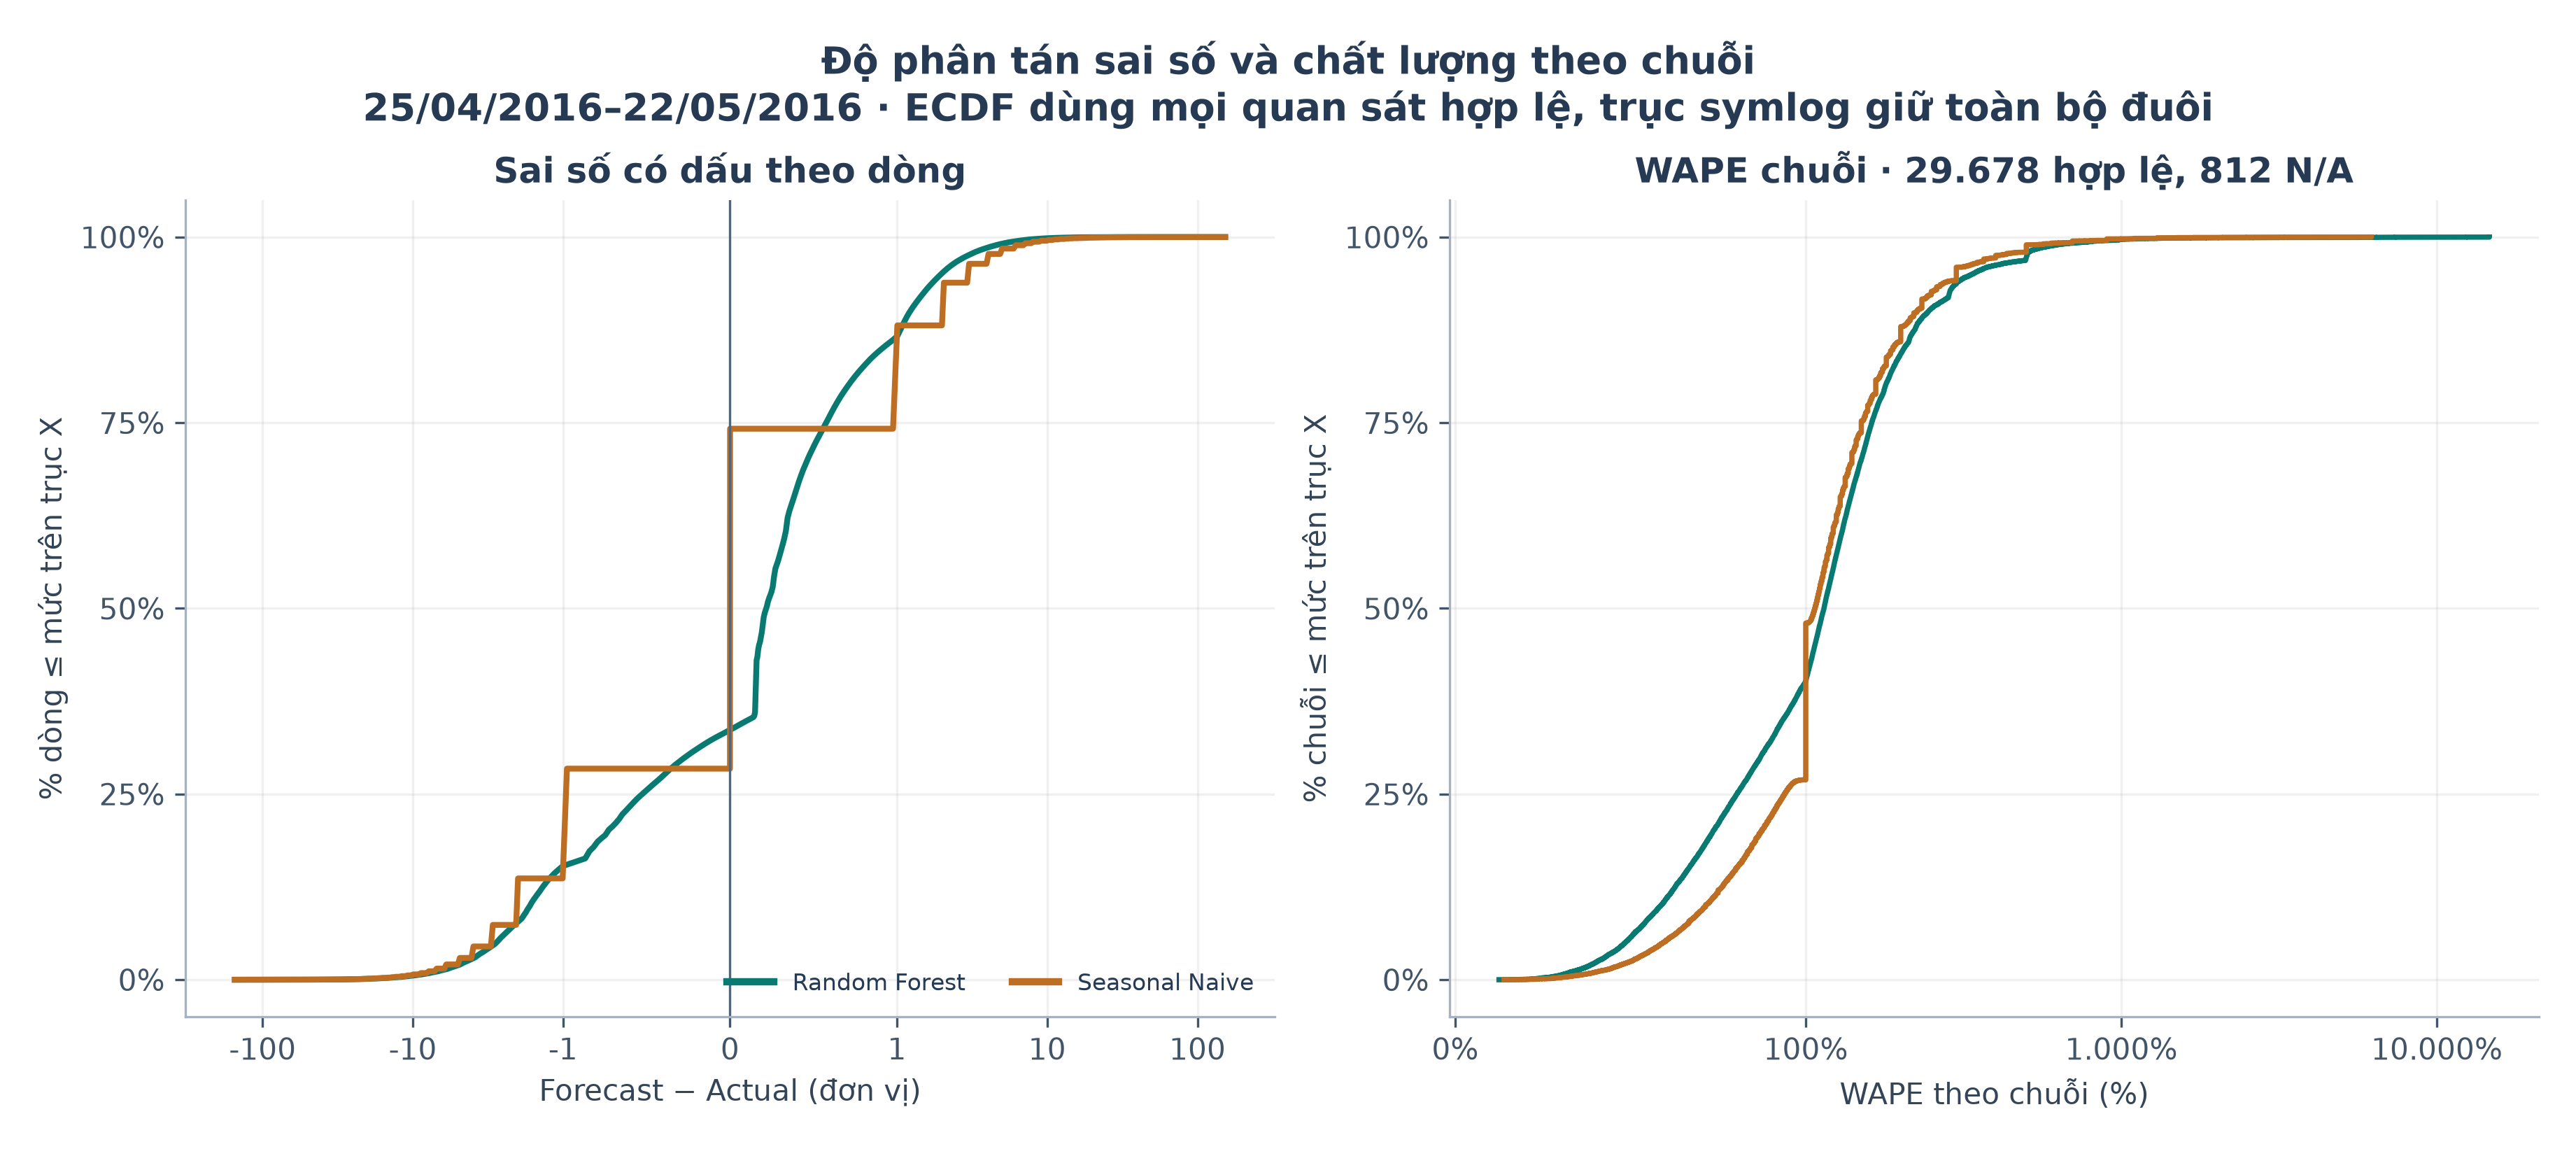

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,zero_actual,observations,rf_mae,sn_mae,rf_mean_forecast,sn_mean_forecast,rf_mean_error,sn_mean_error,rf_wape_pct,rf_bias_pct
0,False,388995,1.6140,2.0846,2.2623,2.2879,-0.9042,-0.8786,50.9713,-28.5556
1,True,464725,0.6422,0.5404,0.6422,0.5404,0.6422,0.5404,NaN,NaN


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,dimension,group,outcome,n_series,share_pct
0,all_series,Toàn bộ,Random Forest thấp hơn,18161,59.5638
1,all_series,Toàn bộ,Tương đương,15,0.0492
2,all_series,Toàn bộ,Seasonal Naive thấp hơn,12314,40.3870
3,state_id,CA,Random Forest thấp hơn,7757,63.6028
4,state_id,CA,Tương đương,4,0.0328
5,state_id,CA,Seasonal Naive thấp hơn,4435,36.3644
6,state_id,TX,Random Forest thấp hơn,4995,54.6081
7,state_id,TX,Tương đương,5,0.0547
8,state_id,TX,Seasonal Naive thấp hơn,4147,45.3373
9,state_id,WI,Random Forest thấp hơn,5409,59.1341


In [9]:
figure('business_v2_stability.png')
show('business_v2_zero_actual', ['zero_actual', 'observations', 'rf_mae', 'sn_mae', 'rf_mean_forecast', 'sn_mean_forecast', 'rf_mean_error', 'sn_mean_error', 'rf_wape_pct', 'rf_bias_pct'], 2)
show('business_v2_series_wins', ['dimension', 'group', 'outcome', 'n_series', 'share_pct'], 30)

## 10. SNAP

**Câu hỏi.** Sau khi tính theo số ngày, lượng bán và chất lượng thay đổi ra sao?

- CA có **10** ngày SNAP bật và **18** ngày tắt. Lượng bán bình quân **19.070** và **18.359** đơn vị/ngày.
- Ở CA, WAPE RF lần lượt **75,53%** và **75,16%**; trong FOODS bình quân là **12.520** và **11.909** đơn vị/ngày.

**Ứng dụng.** Dùng lịch SNAP để phân lớp kiểm tra lịch bán. So sánh theo bang có thể chịu ảnh hưởng của thứ trong tuần và cơ cấu SKU.

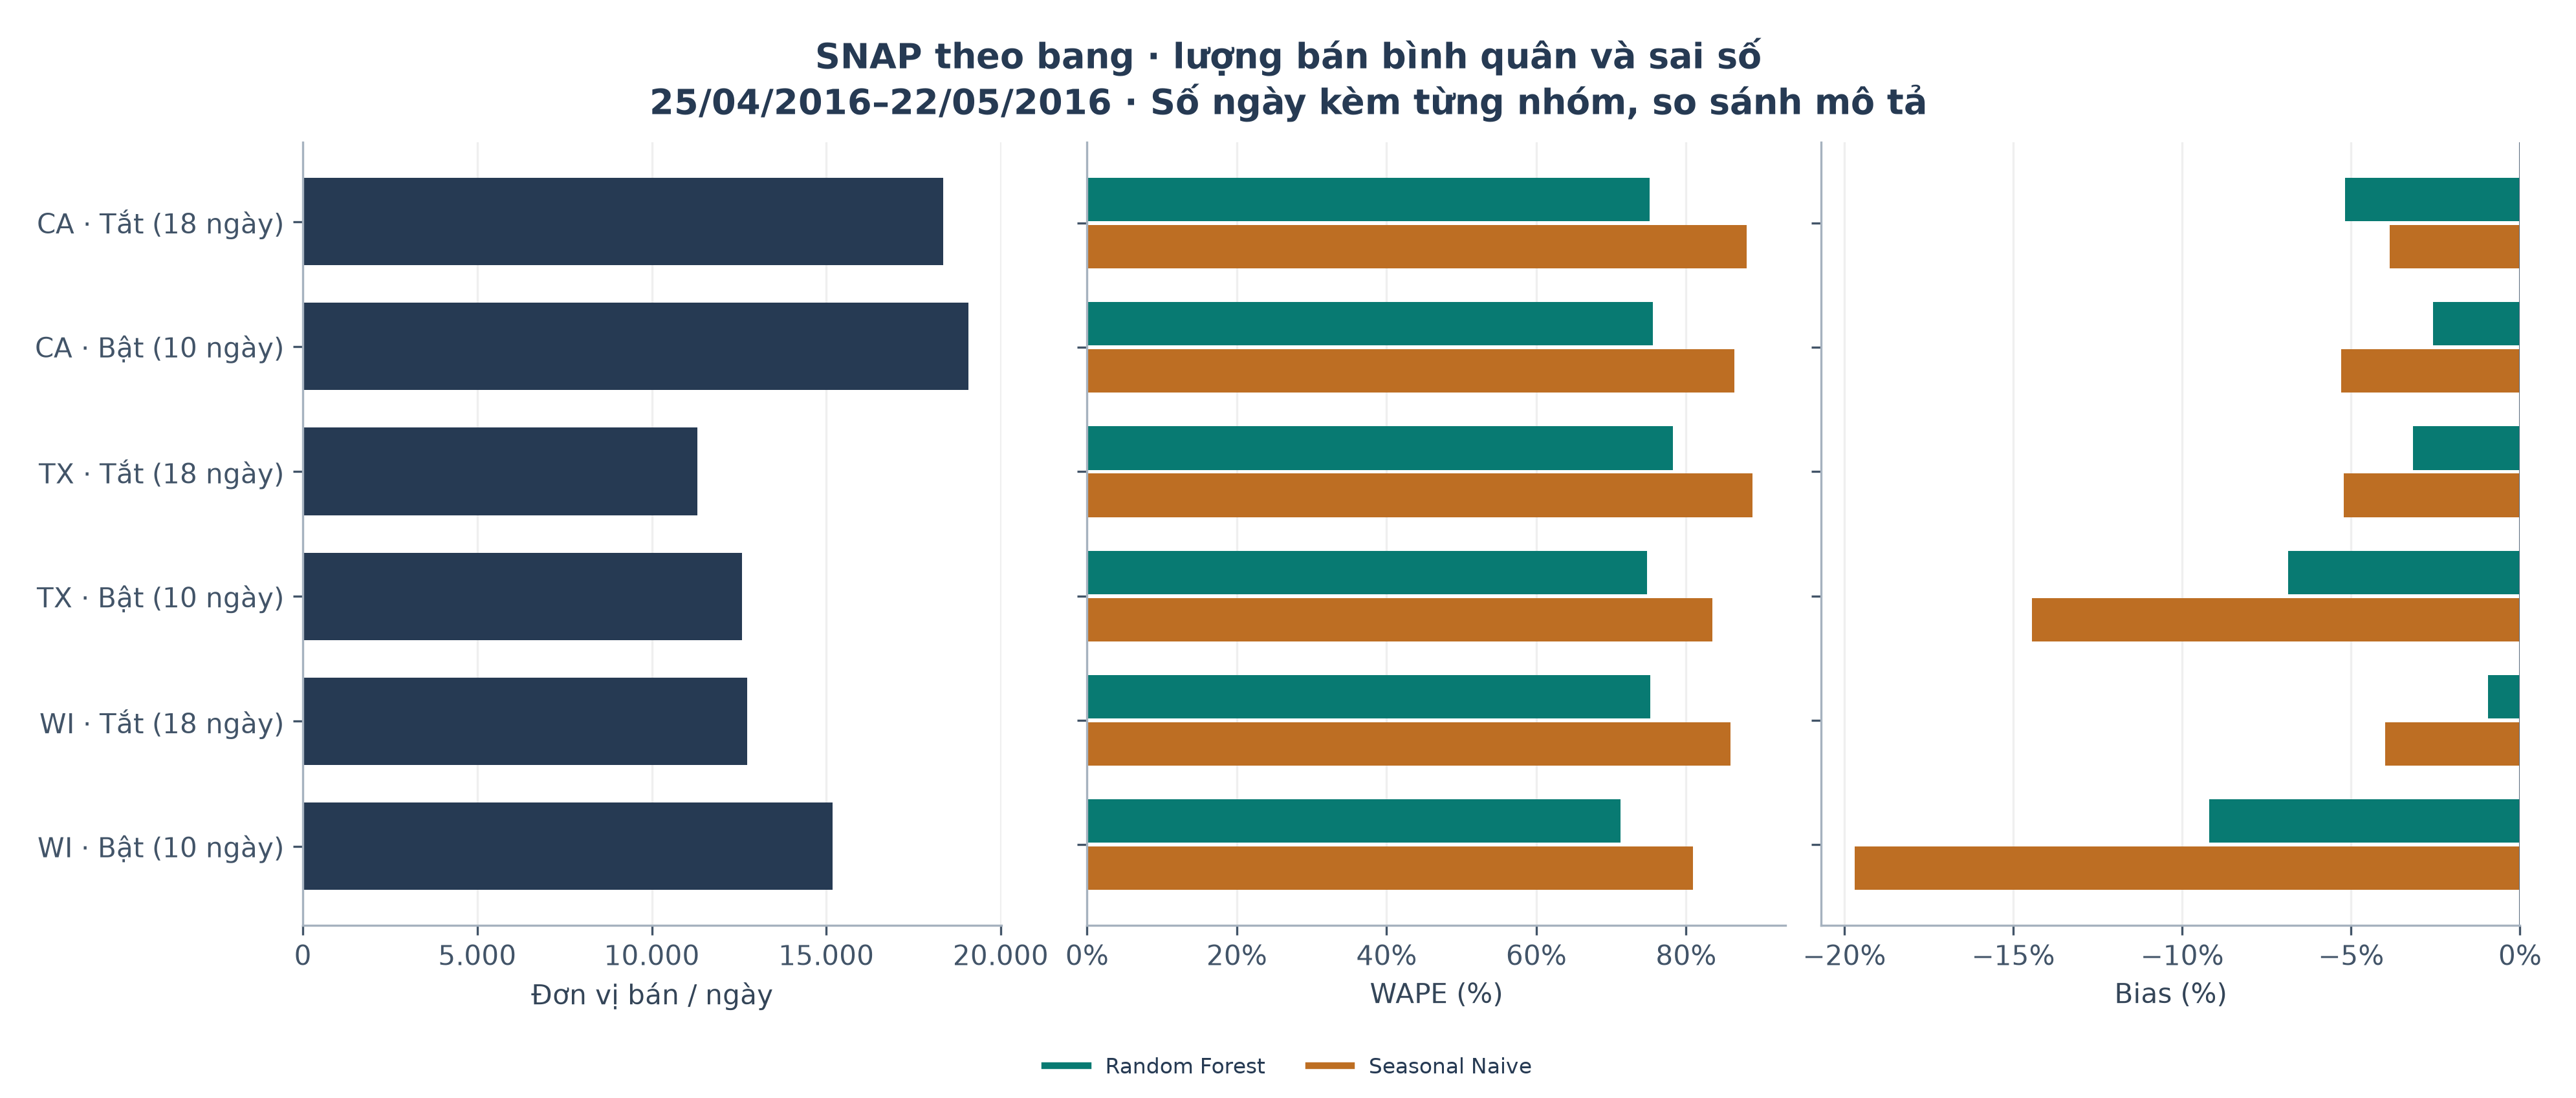

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57488\1711001565.py:11: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  frame = pd.read_csv(tables / (name + ".csv"), float_precision="round_trip")


,scope,state_id,snap_active,n_days,observations,actual_per_day,rf_wape_pct,sn_wape_pct,rf_bias_pct,sn_bias_pct
0,Toàn bộ,CA,False,18,219528,18359.2778,75.1557,88.0875,-5.1763,-3.8509
1,Toàn bộ,CA,True,10,121960,19070.3000,75.5307,86.4779,-2.5845,-5.2920
2,Toàn bộ,TX,False,18,164646,11309.6667,78.1994,88.8630,-3.1784,-5.2109
3,Toàn bộ,TX,True,10,91470,12582.5000,74.7536,83.4850,-6.8655,-14.4415
4,Toàn bộ,WI,False,18,164646,12741.3889,75.2096,85.9626,-0.9569,-3.9874
5,Toàn bộ,WI,True,10,91470,15185.0000,71.2075,80.9285,-9.2007,-19.6944
6,FOODS,CA,False,18,103464,11909.0000,69.1197,80.8203,-5.8032,-4.4812
7,FOODS,CA,True,10,57480,12519.9000,69.6916,78.7426,-3.7880,-7.0280
8,FOODS,TX,False,18,77598,7307.2778,70.9893,80.8327,-3.6880,-4.5738
9,FOODS,TX,True,10,43110,8415.4000,67.3276,75.0802,-10.0274,-17.3741


In [10]:
figure('business_v2_snap.png')
show('business_v2_snap', ['scope', 'state_id', 'snap_active', 'n_days', 'observations', 'actual_per_day', 'rf_wape_pct', 'sn_wape_pct', 'rf_bias_pct', 'sn_bias_pct'], 12)

## 11. Giải thích mô hình

**Câu hỏi.** Rừng sử dụng dữ liệu lịch sử và SNAP như thế nào?

- Rolling Mean chiếm **65,58%** importance, SNAP chiếm **0,45%**.
- Trên Validation, FE-01 đạt **0,664771**, FE-04 đạt **0,623931**, chênh **0,040840** WRMSSE trong lần so sánh hai tập đặc trưng.

**Ứng dụng.** Giữ kiểm tra chất lượng lịch và lags. Importance theo impurity nhạy với số điểm chia và tương quan, chỉ mô tả mức sử dụng đặc trưng.

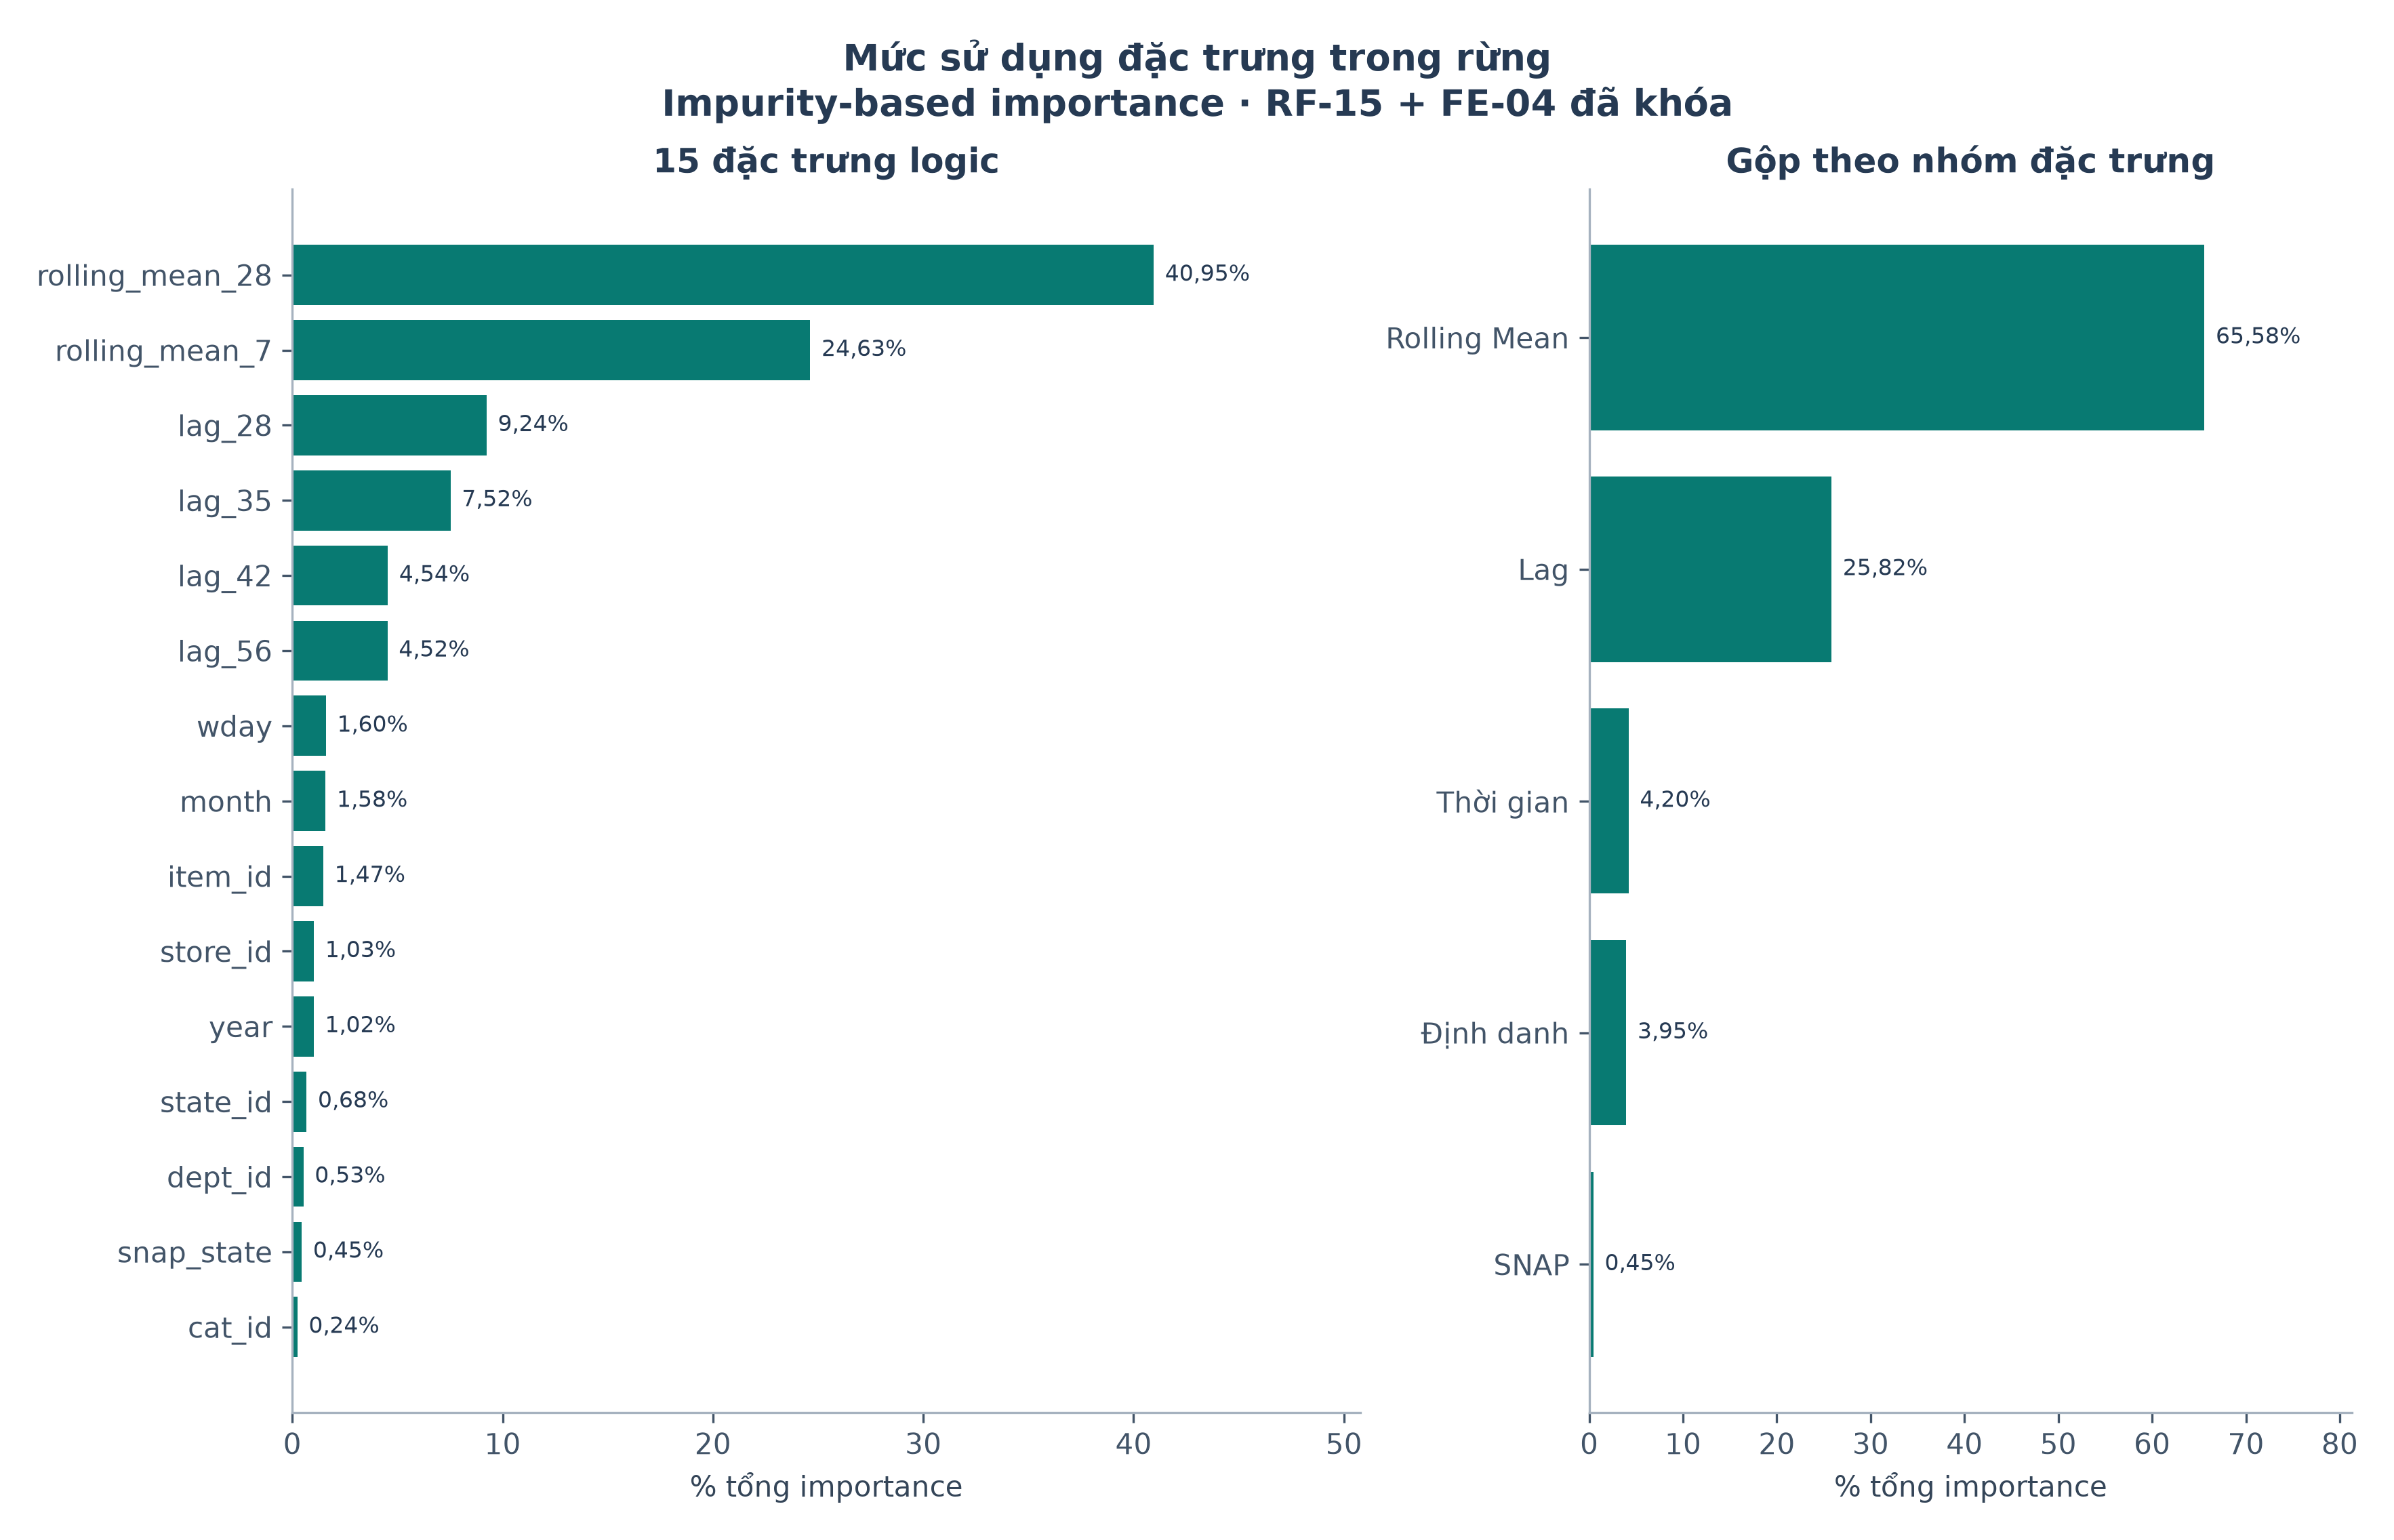

In [11]:
figure('business_v2_importance.png')

## 12. Hàm ý ứng dụng

**Câu hỏi.** Bắt đầu theo dõi ở đâu trong quy trình vận hành?

- Dùng danh sách **CA_1, TX_3** để ưu tiên rà soát dự báo và dùng **CA_2** để kiểm tra chênh lệch tổng lượng.
- Đối chiếu nhóm ABC A và top contribution trước khi chọn chuỗi cần theo dõi. Nhóm A tương ứng **80,00%** doanh thu lịch sử trong cửa sổ trọng số.

**Ứng dụng.** Kết hợp tồn kho khả dụng, lead time, chi phí và mức dịch vụ trước khi quyết định lượng nhập hoặc phân bổ.

## 13. Hạn chế và kết luận

**Câu hỏi.** Kết quả dùng được đến đâu?

- Test gồm 28 ngày và WAPE RF ở độ chi tiết item–store–day vẫn là **75,20%**. Cửa sổ này từng là Validation trong nghiên cứu Mean RMSSE cũ.
- Lợi thế WRMSSE **19,06%** là bằng chứng so với Seasonal Naive trong cửa sổ này. Lượng bán, SNAP và các nhóm minh họa chỉ hỗ trợ phân tích mô tả.

**Ứng dụng.** Kiểm tra lại trên các forecast origin khác và ghép dữ liệu vận hành trước khi quy đổi sai lệch dự báo thành tác động tài chính.